In [1]:
import re
import zipfile
import warnings
import urllib.request
from pathlib import Path
from time import perf_counter
from collections import Counter

import numpy as numpy
import pandas as pandas
import matplotlib.pyplot as plot
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from scipy.optimize import linear_sum_assignment
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA as SkPCA
from sklearn.naive_bayes import GaussianNB as SkGaussianNB
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

In [2]:
# C0

data_url='https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
data_root=Path('data')
data_dir=data_root/'UCI HAR Dataset'
figure_dir=Path('figures')
save_figures=True
col_width, page_width=3.5, 7.16

seed=42
starts=10
max_iterz=1000
convergence=1e-5
m=2
standardize=True
n_components=0.95
moving_ids=(1, 2, 3)
activity_clusters=6
movement_clusters=2

FEATURES_SHOWN=['tBodyAccMag-mean()', 'tBodyAccJerkMag-std()', 'tBodyGyroMag-mean()',
                'tGravityAcc-mean()-X', 'tGravityAcc-mean()-Y', 'angle(X,gravityMean)']
SIT_STAND=('SITTING', 'STANDING')
variance_thresholds=(0.80, 0.90, 0.95, 0.99)
correlation_thresholds=(0.8, 0.9, 0.95, 0.99)
redundancy_threshold=0.95
f_threshold=10
top_features=15
top_sit_stand=10
top_pairs=10
top_loadings=8
pcs_shown=3

alpha=None
n_iters=5000
tol=1e-4
z_clip=500.0
eps=1e-12
threshold=0.5

n_folds=7
lam_grid=(100, 30, 10, 3, 1, 0.3, 0.1)
penalties=('l2', 'l1')
cv_iters=3000
cv_tol=1e-6
component_grid=(0.90, 0.95, 0.99)
intercept_scaling=10
n_jobs=-1

nb_component_grid=(5, 10, 20, 30, 40, 60, 80, 103, 150, 200, 300)
var_smoothing_grid=(1e-9, 1e-6, 1e-3, 1e-2, 1e-1)
nb_check_components=40
top_evidence=10

final_space='No PCA'
final_penalty='l1'
final_lam=30.0
final_n_components=None
nb_final_inputs=30
nb_final_var_smoothing=0.01

bootstrap_draws=2000
bootstrap_seed=7
top_weights=10

In [3]:
# C1

PALETTE={'blue':'#2a78d6', 'orange':'#eb6834', 'gray':'#d3d1c7', 'ink':'#1f1f1e', 'ink2':'#5f5e58'}
SEQUENTIAL=LinearSegmentedColormap.from_list('blue_seq', ['#cde2fb', '#2a78d6', '#0d366b'])
DIVERGING=LinearSegmentedColormap.from_list('blue_gray_red', ['#2a78d6', '#f0efec', '#e34948'])
SHORT={'WALKING':'Walk', 'WALKING_UPSTAIRS':'Upstairs', 'WALKING_DOWNSTAIRS':'Downstairs',
       'SITTING':'Sit', 'STANDING':'Stand', 'LAYING':'Laying'}

plot.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 8, 'axes.titlesize': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': PALETTE['ink2'], 'axes.labelcolor': PALETTE['ink'],
    'xtick.color': PALETTE['ink2'], 'ytick.color': PALETTE['ink2'],
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False})

def save_fig(fig, name):
    if save_figures:
        figure_dir.mkdir(parents=True, exist_ok=True)
        for ext in ('pdf', 'png'):
            fig.savefig(figure_dir/f'{name}.{ext}', bbox_inches='tight')

In [4]:
# C2

def download_data():
    if data_dir.exists():
        return
    data_root.mkdir(exist_ok=True)
    outer=data_root/'har.zip'
    if not outer.exists():
        urllib.request.urlretrieve(data_url, outer)
    with zipfile.ZipFile(outer) as z:
        z.extractall(data_root)
    inner=data_root/'UCI HAR Dataset.zip'
    if inner.exists():
        with zipfile.ZipFile(inner) as z:
            z.extractall(data_root)

def feature_names():
    raw=pandas.read_csv(data_dir/'features.txt', sep=r'\s+', header=None, names=['idx', 'name'])['name'].tolist()
    counts=Counter(raw)
    seen=Counter()
    names=[]
    for n in raw:
        if counts[n] == 1:
            names.append(n)
        else:
            names.append(f"{n}-{'XYZ'[seen[n]]}")
            seen[n] += 1
    return names

def load_split(split, cols):
    d=data_dir/split
    X=pandas.read_csv(d/f'X_{split}.txt', sep=r'\s+', header=None, names=cols)
    y=pandas.read_csv(d/f'y_{split}.txt', header=None).iloc[:, 0].rename('activity')
    s=pandas.read_csv(d/f'subject_{split}.txt', header=None).iloc[:, 0].rename('subject')
    return X, y, s

download_data()
cols=feature_names()
X_train_raw, y_train_raw, subject_train=load_split('train', cols)
X_test_raw, y_test_raw, subject_test=load_split('test', cols)
labels_df=pandas.read_csv(data_dir/'activity_labels.txt', sep=r'\s+', header=None, names=['id', 'name'])
activities=dict(zip(labels_df['id'], labels_df['name']))
activity_order=[activities[i] for i in sorted(activities)]
activity_names=[SHORT[a] for a in activity_order]
dynamic_activities=[activities[i] for i in moving_ids]
n_classes=len(activity_order)

train=pandas.concat([X_train_raw, pandas.DataFrame({'activity': y_train_raw.map(activities), 'subject': subject_train, 'split': 'train'})], axis=1)
test=pandas.concat([X_test_raw, pandas.DataFrame({'activity': y_test_raw.map(activities), 'subject': subject_test, 'split': 'test'})], axis=1)
full=pandas.concat([train, test], ignore_index=True)
print(f'train {X_train_raw.shape} | test {X_test_raw.shape}')

train (7352, 561) | test (2947, 561)


In [5]:
# C3

vals=full[cols].to_numpy()
pandas.Series({
    'windows (train)': len(X_train_raw),
    'windows (test)': len(X_test_raw),
    'features': len(cols),
    'subjects (train / test)': f'{subject_train.nunique()} / {subject_test.nunique()}',
    'missing values': int(full[cols].isna().sum().sum()),
    'constant features': int((full[cols].std() == 0).sum()),
    'duplicate rows': int(full[cols].duplicated().sum()),
    'identical (copied) feature columns': int(full[cols].T.duplicated().sum()),
    'global min / max': f'{vals.min():.3f} / {vals.max():.3f}',
    'values exactly at -1 or +1 (%)': round(100*numpy.isin(vals, [-1.0, 1.0]).mean(), 2),
}).to_frame('value')

,value
windows (train),7352
windows (test),2947
features,561
subjects (train / test),21 / 9
missing values,0
constant features,0
duplicate rows,0
identical (copied) feature columns,21
global min / max,-1.000 / 1.000
values exactly at -1 or +1 (%),1.29


None of the features have missing values, so we don't need to impute anything. The features have a range of -1 ro 1 means the the authors have likely already scaled the features using min / max normilization. Of all the vaules, 1.29% are exactly at +/- -1 so that suggest that some values have been clipped. This also indicates that 21 columns are exact copies and can safely be removed as they don't supply any unique data.

split,train,test,train %,test %
activity,,,,
WALKING,1226,496,16.7,16.8
WALKING_UPSTAIRS,1073,471,14.6,16.0
WALKING_DOWNSTAIRS,986,420,13.4,14.3
SITTING,1286,491,17.5,16.7
STANDING,1374,532,18.7,18.1
LAYING,1407,537,19.1,18.2


largest / smallest class ratio: {'train': 1.43, 'test': 1.28}


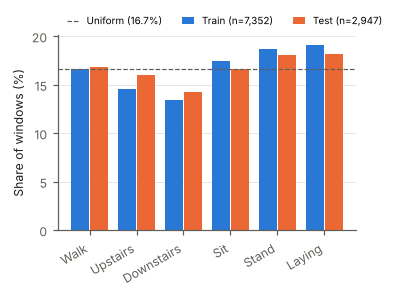

In [6]:
# C4

counts=pandas.crosstab(full['activity'], full['split']).reindex(activity_order)[['train', 'test']]
pct=counts/counts.sum()*100
display(counts.join(pct.round(1).add_suffix(' %')))
print('largest / smallest class ratio:', (counts.max()/counts.min()).round(2).to_dict())

fig, ax=plot.subplots(figsize=(col_width, 2.3))
x=numpy.arange(n_classes)
w=0.38
ax.bar(x-w/2-0.01, pct['train'], w, color=PALETTE['blue'], label=f"Train (n={counts['train'].sum():,})")
ax.bar(x+w/2+0.01, pct['test'], w, color=PALETTE['orange'], label=f"Test (n={counts['test'].sum():,})")
ax.axhline(100/n_classes, color=PALETTE['ink2'], lw=0.8, ls='--', label=f'Uniform ({100/n_classes:.1f}%)')
ax.set_xticks(x, activity_names, rotation=30, ha='right')
ax.set_ylabel('Share of windows (%)')
ax.grid(axis='x', visible=False)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3, fontsize=6.5, handlelength=1.2)
save_fig(fig, 'class_balance')
plot.show()

The windows are fairly balanced and the train and test sets for each class. There are some slight imbalances with the highest number of classes being laying with 1407 and the lowest being walking_downstairs with 986, but this is close enough that I'm making the decision to treat it as a balaced dataset. I doesn't appear to me that we need to do any resampling or weights for the classes because the class difference is only 1.4x. For this dataset, we can report the Macro F1-Score, accurance and the confusion matrix. We'll primarilary evaluate the data using the Macro F1 score, we'll use accuracy because the dataset only has a slight imbalance and the confusion matrix.

train subjects: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
test subjects:  [2, 4, 9, 10, 12, 13, 18, 20, 24]
overlap: none
count     30.0
mean     343.3
std       35.7
min      281.0
25%      317.8
50%      342.5
75%      371.0
max      409.0


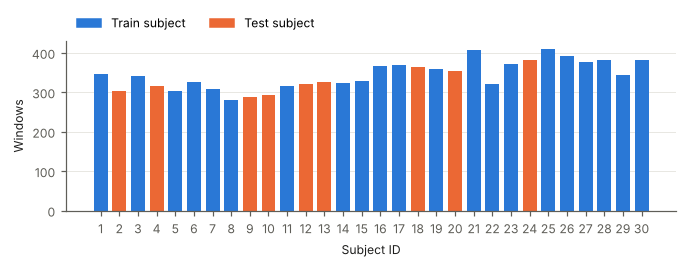

smallest subject x activity cell: 36 | largest: 95


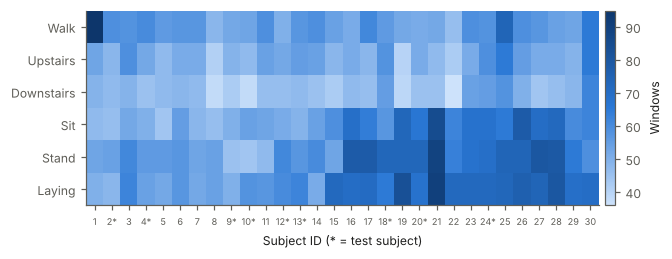

In [7]:
# C5

train_subjects, test_subjects=set(subject_train), set(subject_test)
print('train subjects:', sorted(train_subjects))
print('test subjects: ', sorted(test_subjects))
print('overlap:', sorted(train_subjects & test_subjects) or 'none')
per_subject=full.groupby('subject').size()
split_of=full.groupby('subject')['split'].first()
print(per_subject.describe().round(1).to_string())

fig, ax=plot.subplots(figsize=(page_width, 2.0))
ax.bar(per_subject.index.astype(str), per_subject.values, width=0.75,
       color=[PALETTE['blue'] if split_of[s] == 'train' else PALETTE['orange'] for s in per_subject.index])
ax.legend([Patch(color=PALETTE['blue']), Patch(color=PALETTE['orange'])], ['Train subject', 'Test subject'],
          loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2)
ax.set_xlabel('Subject ID')
ax.set_ylabel('Windows')
ax.grid(axis='x', visible=False)
save_fig(fig, 'windows_per_subject')
plot.show()

sa=pandas.crosstab(full['subject'], full['activity']).reindex(columns=activity_order)
print('smallest subject x activity cell:', sa.values.min(), '| largest:', sa.values.max())
fig, ax=plot.subplots(figsize=(page_width, 2.3))
im=ax.imshow(sa.T.values, aspect='auto', cmap=SEQUENTIAL)
ax.set_yticks(range(n_classes), activity_names)
ax.set_xticks(range(len(sa)), [f'{s}*' if s in test_subjects else str(s) for s in sa.index], fontsize=6)
ax.set_xlabel('Subject ID (* = test subject)')
ax.grid(False)
fig.colorbar(im, ax=ax, label='Windows', pad=0.01)
save_fig(fig, 'subject_activity_heatmap')
plot.show()

A subject-disjoint test gives a measurement of how well the model is able to process features from test subjects that are completley unseen. We can see from the heat map and the face that there are no features with missing data that every test subject participates in every activity. When cross-validation is done, we will need to remain aware of the groups when the splits are performed. Using sci-kit learn, we will use GroupKFold matching on the participant ID as the variable to use for grouping. If we didn't pay attention to grouping when performing the split for cross-validation the same participants could be added to the training and validation sets which would result in artifically high cross-validation scores.

In [8]:
# C6

PAT=re.compile(r'([tf])((?:Body)+|Gravity)(Acc|Gyro)(Jerk)?(Mag)?-([A-Za-z]+)')

def family(name):
    if name.startswith('angle('):
        return 'angle', 'angle', 'angle'
    match=PAT.match(name)
    signal=('Body' if match[2].startswith('Body') else 'Gravity')+match[3]+(match[4] or '')+(match[5] or '')
    return {'t': 'time', 'f': 'frequency'}[match[1]], signal, match[6]

fam=pandas.DataFrame([family(f) for f in cols], index=cols, columns=['domain', 'signal', 'statistic'])
display(pandas.crosstab(fam['signal'], fam['domain'], margins=True))
display(pandas.crosstab(fam['statistic'], fam['domain'], margins=True))

domain,angle,frequency,time,All
signal,,,,
BodyAcc,0,79,40,119
BodyAccJerk,0,79,40,119
BodyAccJerkMag,0,13,13,26
BodyAccMag,0,13,13,26
BodyGyro,0,79,40,119
BodyGyroJerk,0,0,40,40
BodyGyroJerkMag,0,13,13,26
BodyGyroMag,0,13,13,26
GravityAcc,0,0,40,40


domain,angle,frequency,time,All
statistic,,,,
angle,7,0,0,7
arCoeff,0,0,80,80
bandsEnergy,0,126,0,126
correlation,0,0,15,15
energy,0,13,20,33
entropy,0,13,20,33
iqr,0,13,20,33
kurtosis,0,13,0,13
mad,0,13,20,33


This dataset comes from two seperate sensors: a 3-axis accelerometer and a gyroscope. This sensors each provide movement data on the X, Y and Z plane and the other data points all appear to be mathmatically derived from that data from both sensors. This is apparent by looking at the coloum names that specify what was used; for example tGravityAcc-max()-Y uses max/min and tBodyAccJerkMag-std() uses standard deviation to derive their values. It's also obvious by the fact there are 561 datapoints that originate from only two sensors which would only be possible using the original ten signals in addition to the angle features and each of those are summarized by up to 17 statitistics. Because most of the geatures were generated from the same basic data, they will move simultanously as the input data changes. We will need to look at processing the data using L1 regularization or PCA to remove the overlapping derived data.

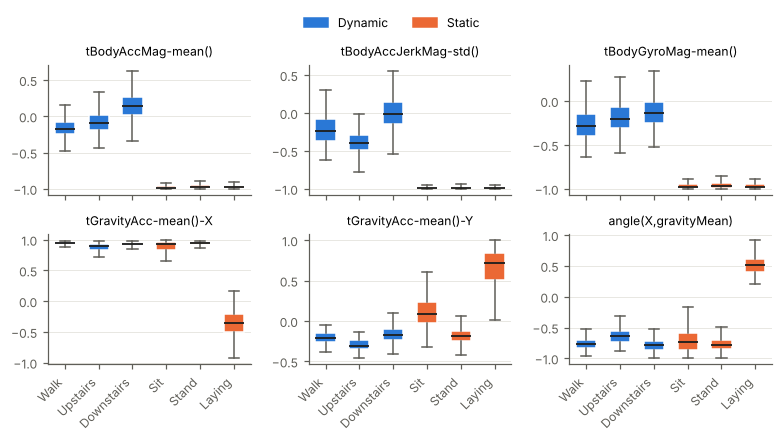

In [9]:
# C7

fig, axes=plot.subplots(2, 3, figsize=(page_width, 4.0), sharex=True)
for ax, f in zip(axes.flat, FEATURES_SHOWN):
    bp=ax.boxplot([train.loc[train['activity'] == a, f] for a in activity_order], widths=0.6,
                  patch_artist=True, showfliers=False, medianprops=dict(color=PALETTE['ink'], lw=1.2),
                  whiskerprops=dict(color=PALETTE['ink2']), capprops=dict(color=PALETTE['ink2']))
    for a, box in zip(activity_order, bp['boxes']):
        box.set(facecolor=PALETTE['blue'] if a in dynamic_activities else PALETTE['orange'], edgecolor='white', linewidth=1)
    ax.set_title(f, fontsize=8)
    ax.set_xticks(range(1, n_classes+1), activity_names, rotation=45, ha='right')
    ax.grid(axis='x', visible=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.legend([Patch(color=PALETTE['blue']), Patch(color=PALETTE['orange'])], ['Dynamic', 'Static'],
           loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.0))
save_fig(fig, 'feature_boxplots')
plot.show()

The data is split by dynamic / kinetic activities like walking, going up stairs and going downstairs and static activities like sitting, standing or lying down. If you look at the sitting and standing groups, most individual features are difficult to tell apart. Also, features like sitting and standign would be hard to break appart becuase the sensor data (mainly the angle of the sensor relative to the ground) would look very similar and most of the sitting activities have a value of about -1. When the participant is laying down, the features tGravityAcc-mean()-X and angle(X,gravityMean) help to separate it.

median F over 561 features: 1463; features with F < 10: 10


,F (6 classes),domain,signal,statistic
fBodyAccJerk-entropy()-X,36918.0,frequency,BodyAccJerk,entropy
tGravityAcc-mean()-X,29363.0,time,GravityAcc,mean
tGravityAcc-min()-X,28175.0,time,GravityAcc,min
fBodyAccJerk-entropy()-Y,28116.0,frequency,BodyAccJerk,entropy
tGravityAcc-max()-X,26687.0,time,GravityAcc,max
tGravityAcc-energy()-X,25982.0,time,GravityAcc,energy
fBodyBodyAccJerkMag-entropy(),23619.0,frequency,BodyAccJerkMag,entropy
tBodyAccJerkMag-entropy(),23437.0,time,BodyAccJerkMag,entropy
fBodyAcc-entropy()-X,23222.0,frequency,BodyAcc,entropy
tBodyAccJerk-entropy()-X,22267.0,time,BodyAccJerk,entropy


Sitting vs standing: best F = 2816; median F = 10.1


,F (sit vs stand),domain,signal,statistic
tGravityAcc-max()-Y,2816.0,time,GravityAcc,max
tGravityAcc-mean()-Y,2798.5,time,GravityAcc,mean
"angle(Y,gravityMean)",2690.3,angle,angle,angle
tGravityAcc-min()-Y,2571.4,time,GravityAcc,min
fBodyGyro-meanFreq()-X,821.1,frequency,BodyGyro,meanFreq
"tGravityAcc-correlation()-X,Y",707.8,time,GravityAcc,correlation
tGravityAcc-max()-Z,651.5,time,GravityAcc,max
"angle(Z,gravityMean)",641.1,angle,angle,angle
tGravityAcc-mean()-Z,637.5,time,GravityAcc,mean
tGravityAcc-entropy()-Y,610.4,time,GravityAcc,entropy


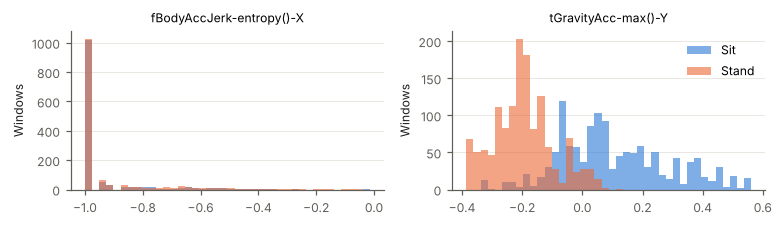

In [10]:
# C8

def anova_f(X, y):
    X=numpy.asarray(X, dtype=float)
    y=numpy.asarray(y)
    classes=numpy.unique(y)
    n, k=len(y), len(classes)
    grand=X.mean(axis=0)
    ssb=sum((y == c).sum()*(X[y == c].mean(axis=0)-grand)**2 for c in classes)
    ssw=sum(((X[y == c]-X[y == c].mean(axis=0))**2).sum(axis=0) for c in classes)
    return (ssb/(k-1))/(ssw/(n-k))

F_all=pandas.Series(anova_f(X_train_raw, y_train_raw), index=cols).sort_values(ascending=False)
print(f'median F over {len(cols)} features: {F_all.median():.0f}; features with F < {f_threshold}: {(F_all < f_threshold).sum()}')
display(F_all.head(top_features).round(0).to_frame('F (6 classes)').join(fam))

ss=train['activity'].isin(SIT_STAND)
F_ss=pandas.Series(anova_f(train.loc[ss, cols], train.loc[ss, 'activity']), index=cols).sort_values(ascending=False)
print(f'Sitting vs standing: best F = {F_ss.iloc[0]:.0f}; median F = {F_ss.median():.1f}')
display(F_ss.head(top_sit_stand).round(1).to_frame('F (sit vs stand)').join(fam))

fig, axes=plot.subplots(1, 2, figsize=(page_width, 2.1))
for ax, f in zip(axes, [F_all.index[0], F_ss.index[0]]):
    bins=numpy.linspace(train.loc[ss, f].min(), train.loc[ss, f].max(), 41)
    for a, c in zip(SIT_STAND, (PALETTE['blue'], PALETTE['orange'])):
        ax.hist(train.loc[train['activity'] == a, f], bins=bins, color=c, alpha=0.6, label=SHORT[a])
    ax.set_title(f, fontsize=8)
    ax.set_ylabel('Windows')
    ax.grid(axis='x', visible=False)
axes[1].legend(loc='upper right')
fig.tight_layout()
save_fig(fig, 'sit_vs_stand')
plot.show()

The best comparison of sitting and standing features in this dataset has an F value of 2,816 and the six class F values has a median F score of 1,463 and a top F-score of 36,918. There are only a few features in the sitting and standing groups that are useful but amonge those the F-values are still fairly low. 

The standing and sitting feature groups appear to be similiar in the data with a F-value of 10.1; that means that most of the features appear to be the same weather or not the participant is sitting or standing. There are two features that are noticibly different in the sitting / standing classes and those are tGravityAcc-max()-Y and angle(Y,gravityMean).Those two features represent the orientation of the phone worn on the participants waist, which would be in a different alignment if they were sitting or standing. Based on what I'm seeing here, the confusion matrix is likely to show the most misclassification around the sitting and standing classes.

per-feature means range -0.98 .. 0.83
per-feature stds  range 0.041 .. 0.752


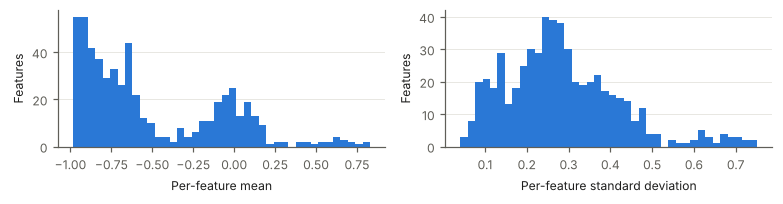

In [11]:
# C9

desc=X_train_raw.describe().T
print(f"per-feature means range {desc['mean'].min():.2f} .. {desc['mean'].max():.2f}")
print(f"per-feature stds  range {desc['std'].min():.3f} .. {desc['std'].max():.3f}")
fig, axes=plot.subplots(1, 2, figsize=(page_width, 1.9))
axes[0].hist(desc['mean'], bins=40, color=PALETTE['blue'])
axes[0].set_xlabel('Per-feature mean')
axes[1].hist(desc['std'], bins=40, color=PALETTE['blue'])
axes[1].set_xlabel('Per-feature standard deviation')
for ax in axes:
    ax.set_ylabel('Features')
    ax.grid(axis='x', visible=False)
fig.tight_layout()
save_fig(fig, 'feature_scale')
plot.show()

It appears that the scales of the features don't match up and will need to be standardized so that they all have a standard deviation of 1 and a mean of 0. If we don't K-Means (and other algorythems) will have issues representing the data. For example, K-Means uses Euclidean distance do the features that have wider ranges will overpower the others and cause the representation to be skewed; PCA looks for the largest variance so if the data is unscaled features that naturally have a larger standard deviation will be prioritized; gradient descent doesn't do well with unscaled datasets and would cause the optimizer to use routes that are not efficient.

157,080 feature pairs
  |r| > 0.8: 23,058 pairs (14.7%)
  |r| > 0.9:  8,206 pairs (5.2%)
  |r| > 0.95:  2,281 pairs (1.5%)
  |r| > 0.99:    207 pairs (0.1%)
features with at least one partner at |r| > 0.95: 391 of 561


,feature A,feature B,r
0,tBodyAccMag-arCoeff()3,tGravityAccMag-arCoeff()3,1.0
1,fBodyBodyGyroMag-mean(),fBodyBodyGyroMag-sma(),1.0
2,tBodyGyroMag-mean(),tBodyGyroMag-sma(),1.0
3,tBodyAccJerkMag-mean(),tBodyAccJerkMag-sma(),1.0
4,tBodyAccMag-iqr(),tGravityAccMag-iqr(),1.0
5,tBodyAccMag-mad(),tGravityAccMag-mad(),1.0
6,tBodyAccMag-entropy(),tGravityAccMag-entropy(),1.0
7,fBodyBodyAccJerkMag-mean(),fBodyBodyAccJerkMag-sma(),1.0
8,tBodyGyroJerkMag-mean(),tBodyGyroJerkMag-sma(),1.0
9,tBodyAccMag-max(),tGravityAccMag-max(),1.0


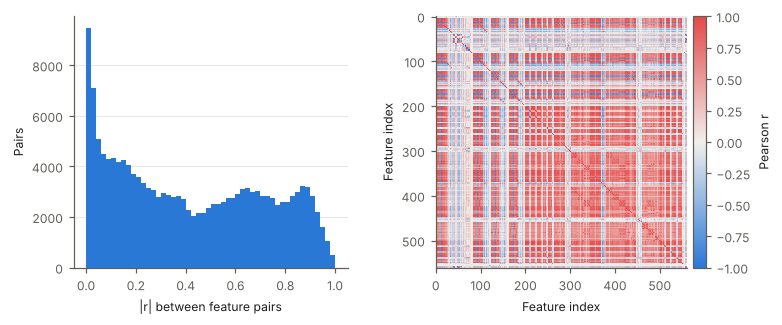

In [12]:
# C10

C=numpy.corrcoef(X_train_raw.to_numpy(), rowvar=False)
iu=numpy.triu_indices_from(C, k=1)
r=numpy.abs(C[iu])
print(f'{len(r):,} feature pairs')
for t in correlation_thresholds:
    print(f'  |r| > {t}: {(r > t).sum():>6,} pairs ({100*(r > t).mean():.1f}%)')
partner=numpy.abs(C) > redundancy_threshold
numpy.fill_diagonal(partner, False)
print(f'features with at least one partner at |r| > {redundancy_threshold}: {partner.any(axis=1).sum()} of {len(cols)}')
top=numpy.argsort(-r)[:top_pairs]
display(pandas.DataFrame({'feature A': [cols[i] for i in iu[0][top]], 'feature B': [cols[j] for j in iu[1][top]],
                          'r': C[iu][top].round(4)}))

fig, axes=plot.subplots(1, 2, figsize=(page_width, 3.0), gridspec_kw=dict(width_ratios=[1, 1.15]))
axes[0].hist(r, bins=50, color=PALETTE['blue'])
axes[0].set_xlabel('|r| between feature pairs')
axes[0].set_ylabel('Pairs')
axes[0].grid(axis='x', visible=False)
im=axes[1].imshow(C, cmap=DIVERGING, vmin=-1, vmax=1, interpolation='nearest')
axes[1].set_xlabel('Feature index')
axes[1].set_ylabel('Feature index')
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], label='Pearson r', fraction=0.046, pad=0.02)
fig.tight_layout()
save_fig(fig, 'correlation')
plot.show()

Almost 15% of the feature pairs have a coorleation of |r| > 0.8 and 391 of the 561 features are matched with a feature that has a coorelation of |r| > 0.95. This measts that the dataset has many features that are redundant. There are also some feature pairs like fBodyBodyGyroMag-mean() and fBodyBodyGyroMag-sma() that have a perfect coorelation of 1.0. This means that for the 391 features that are redundent, adding them to the model only adds complexity without adding any much new information and also makes overfitting more likely. These redundent features make it necessary to perform steps like PCA to remove the redundency. When there are logistic regression coefficients they can become unstable when there is collinearity and the signs can flip. L1 has a tendenancy to keep one feature abritrarily from a correlated group and L2 will spread the weight across the group.

,80% variance,90% variance,95% variance,99% variance
centered only,10,34,67,155
standardized,26,63,102,179


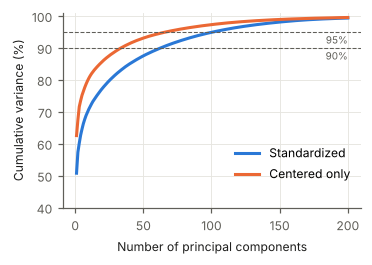

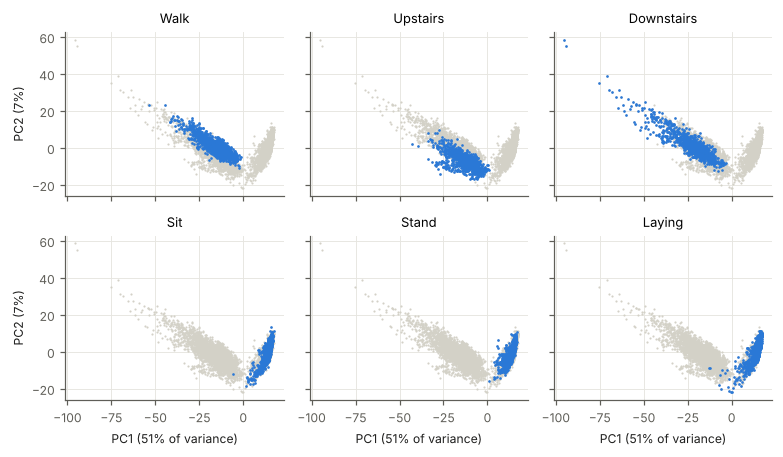

In [13]:
# C11

mu, sd=X_train_raw.mean(), X_train_raw.std(ddof=0)
Z_preview=((X_train_raw-mu)/sd).to_numpy()
U, S, Vt=numpy.linalg.svd(Z_preview, full_matrices=False)
cum_std=numpy.cumsum(S**2)/numpy.sum(S**2)
S_raw=numpy.linalg.svd(X_train_raw.to_numpy()-X_train_raw.to_numpy().mean(axis=0), compute_uv=False)
cum_raw=numpy.cumsum(S_raw**2)/numpy.sum(S_raw**2)
display(pandas.DataFrame({t: [int(numpy.searchsorted(cum_raw, t)+1), int(numpy.searchsorted(cum_std, t)+1)]
                          for t in variance_thresholds},
                         index=['centered only', 'standardized']).rename(columns=lambda t: f'{t:.0%} variance'))

k_axis=numpy.arange(1, 201)
fig, ax=plot.subplots(figsize=(col_width, 2.3))
ax.plot(k_axis, cum_std[:200]*100, color=PALETTE['blue'], lw=2, label='Standardized')
ax.plot(k_axis, cum_raw[:200]*100, color=PALETTE['orange'], lw=2, label='Centered only')
for t in (90, 95):
    ax.axhline(t, color=PALETTE['ink2'], lw=0.7, ls='--')
    ax.text(k_axis[-1], t-0.6, f'{t}%', ha='right', va='top', fontsize=6.5, color=PALETTE['ink2'])
ax.set_xlabel('Number of principal components')
ax.set_ylabel('Cumulative variance (%)')
ax.set_ylim(40, 101)
ax.legend(loc='lower right', bbox_to_anchor=(1, 0.08))
save_fig(fig, 'pca_cumulative_variance')
plot.show()

scores=U[:, :2]*S[:2]
evr_preview=S**2/numpy.sum(S**2)
act=train['activity'].to_numpy()
fig, axes=plot.subplots(2, 3, figsize=(page_width, 4.2), sharex=True, sharey=True)
for ax, a in zip(axes.flat, activity_order):
    ax.scatter(scores[:, 0], scores[:, 1], s=2, color=PALETTE['gray'], linewidths=0, rasterized=True)
    mask=act == a
    ax.scatter(scores[mask, 0], scores[mask, 1], s=3, color=PALETTE['blue'], linewidths=0, rasterized=True)
    ax.set_title(SHORT[a], fontsize=8.5)
for ax in axes[1]:
    ax.set_xlabel(f'PC1 ({evr_preview[0]:.0%} of variance)')
for ax in axes[:, 0]:
    ax.set_ylabel(f'PC2 ({evr_preview[1]:.0%})')
fig.tight_layout()
save_fig(fig, 'pca_2d_by_activity')
plot.show()

We would examine the PCA variance curve and keep the components that are required to capture somwhere around 90-95% of the variance, so roughly 103 of the 561 original features. These will allow us to retain the useful signals and elminate the excess redundant information that would just add computational complexity without adding new information. The features that overlap are the clusters representing sitting and standing; activities like walking, going up and down stairs seperate from more static activities like sitting, standing and laying down. Sitting and standing are represented on the same areas of the chart, so K-Means or FCM will not be able to seperate them; K-Means would likely just lump both sitting and standing together.

GroupKFold will be used with the subjectID in the traing set so that there isn't any data leaked between the training and test sets; this is required becuase the data has multiple sequential windows for each participant. 

The 561 features that are derived from the original six sets of data will need to have PCA applied to reduce the independent components. 

We'll use logistic regression so that the results can be validated against the more complete non-linear models.

The classes are only mildly imbalanced so looking at Accuracy is valid, but we'll use the Macro F1-score and a confusion matrix as the primary metrics to see if the model can resolved the overlapping sitting and standing features.

In [14]:
# C12

def remap_labels(y):
    return numpy.asarray(y, dtype=int)-1

class DropDuplicateColumns(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.keep_=[]
        self.dropped_={}
        for col in X.columns:
            original=next((old for old in self.keep_ if X[col].equals(X[old])), None)
            if original is None:
                self.keep_.append(col)
            else:
                self.dropped_[col]=original
        return self

    def transform(self, X):
        return X.loc[:, self.keep_]

class Standardizer(BaseEstimator, TransformerMixin):
    def __init__(self, with_std=True):
        self.with_std=with_std

    def fit(self, X, y=None):
        X=numpy.asarray(X, dtype=float)
        self.mean_=X.mean(axis=0)
        self.std_=X.std(axis=0, ddof=0) if self.with_std else numpy.ones(X.shape[1])
        self.std_[self.std_ == 0]=1.0
        return self

    def transform(self, X):
        return (numpy.asarray(X, dtype=float)-self.mean_)/self.std_

class PCA(BaseEstimator, TransformerMixin):
    def __init__(self, n_components=None):
        self.n_components=n_components

    def fit(self, Z, y=None):
        Z=numpy.asarray(Z, dtype=float)
        self.mean_=Z.mean(axis=0)
        _, singular, directions=numpy.linalg.svd(Z-self.mean_, full_matrices=False)
        variance=singular**2
        self.explained_variance_ratio_all_=variance/variance.sum()
        rank=len(singular)
        if self.n_components is None:
            k=rank
        elif isinstance(self.n_components, (int, numpy.integer)):
            k=int(self.n_components)
        else:
            k=int(numpy.searchsorted(numpy.cumsum(self.explained_variance_ratio_all_), self.n_components)+1)
        self.n_components_=k
        self.components_=directions[:k]
        self.explained_variance_ratio_=self.explained_variance_ratio_all_[:k]
        return self

    def transform(self, Z):
        return (numpy.asarray(Z, dtype=float)-self.mean_)@self.components_.T

    def inverse_transform(self, T):
        return numpy.asarray(T, dtype=float)@self.components_+self.mean_

def make_prep(n_components, standardize=True):
    return make_pipeline(DropDuplicateColumns(), Standardizer(with_std=standardize), PCA(n_components=n_components))

y_train=remap_labels(y_train_raw)
y_test=remap_labels(y_test_raw)
assert not X_train_raw.isna().any().any() and not X_test_raw.isna().any().any()
print(dict(enumerate(activity_order)))
print('no missing values in train or test')

{0: 'WALKING', 1: 'WALKING_UPSTAIRS', 2: 'WALKING_DOWNSTAIRS', 3: 'SITTING', 4: 'STANDING', 5: 'LAYING'}
no missing values in train or test


Nothing needs to be imputed with the dataset becuase there aren't any features with missing values. All of the features are scalled with a range of -1 to 1, so the original researchers have likely already applied minimum / maximum scaling. Since the values are scaled to that range, we can't perform any type of outlier removal because that would most likely just clop off valid data.

In [15]:
# C13

dedup=DropDuplicateColumns().fit(X_train_raw)
print(f'kept {len(dedup.keep_)} of {X_train_raw.shape[1]} columns; dropped {len(dedup.dropped_)}')
same_in_test=sum(X_test_raw[c].equals(X_test_raw[o]) for c, o in dedup.dropped_.items())
print(f'pairs still identical in test: {same_in_test} of {len(dedup.dropped_)}')
X_train_clean=dedup.transform(X_train_raw)
X_test_clean=dedup.transform(X_test_raw)
pandas.Series(dedup.dropped_, name='copy of').rename_axis('dropped column').to_frame()

kept 540 of 561 columns; dropped 21
pairs still identical in test: 21 of 21


,copy of
dropped column,
tBodyAccMag-sma(),tBodyAccMag-mean()
tGravityAccMag-mean(),tBodyAccMag-mean()
tGravityAccMag-std(),tBodyAccMag-std()
tGravityAccMag-mad(),tBodyAccMag-mad()
tGravityAccMag-max(),tBodyAccMag-max()
tGravityAccMag-min(),tBodyAccMag-min()
tGravityAccMag-sma(),tBodyAccMag-mean()
tGravityAccMag-energy(),tBodyAccMag-energy()
tGravityAccMag-iqr(),tBodyAccMag-iqr()


There were 21 columns that were identical so those were dropped reducing the number of features to 540 from 561.0. The columns that were dropped were mostly from fearures relating to magnitude, for example tGravityAccMag-mean() was dropped becuase it was identical to tBodyAccMag-mean(). The features that were just closely cooreldated and "almost" copies were retained and will go through regularization.

In [16]:
# C14

scaler=Standardizer(with_std=standardize).fit(X_train_clean)
Z_train=scaler.transform(X_train_clean)
Z_test=scaler.transform(X_test_clean)
pandas.DataFrame({
    split: {'max |column mean|': numpy.abs(Z.mean(axis=0)).max(),
            'min column std': Z.std(axis=0).min(),
            'max column std': Z.std(axis=0).max()}
    for split, Z in (('train', Z_train), ('test', Z_test))}).round(3)

,train,test
max |column mean|,0.0,0.203
min column std,1.0,0.583
max column std,1.0,1.180


In [17]:
#testing / validation

ref=StandardScaler(with_std=standardize).fit(X_train_clean)
print(numpy.allclose(Z_train, ref.transform(X_train_clean)), numpy.allclose(Z_test, ref.transform(X_test_clean)))

True True


<!-- We will use z-score standardization which will give every feature a mean of 0 and a standard deviaiton of 1; currently the test features have a standard deviaion range of 0.583 to 1.180 which means that features with a higher variance will dominate the data. The mean value of the test set have a maximum of 0.203, which juse indicates some of the unseen test set data points are different from the training set. We can't compute the mean and standard deviation on the training and test set becuase that would cause data to leak to the test set and would make the output invalid.  -->

The 9 test subjects are different becuase they have different movement characteristics than the subjects in the training sets. We need to apply z-scoring becuase the standard deviation of the raw features have a range from 0.041 to 0.752 or about 18x. The data has already been scaled by maximum / minimum but that doesn't give the features a variance that is equal. We can't compute the mean and standard deviation on the training and test set becuase the test subject statistics would leak and so the results would not just be from the unseen participants.

,80% variance,90% variance,95% variance,99% variance
components needed,27,64,103,179


keeping k = 103 of 540 dimensions = 95.1% of training variance


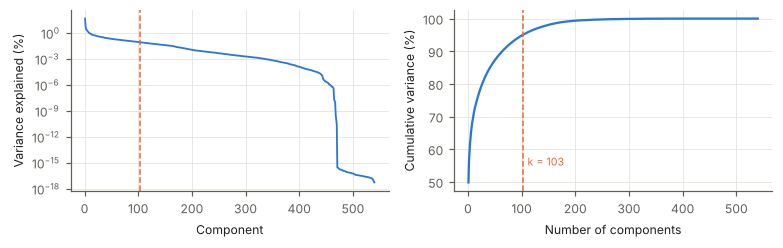

In [18]:
# C15

pca_all=PCA(n_components=None).fit(Z_train)
evr=pca_all.explained_variance_ratio_all_
cum=numpy.cumsum(evr)
display(pandas.Series({f'{t:.0%} variance': int(numpy.searchsorted(cum, t)+1) for t in variance_thresholds},
                      name='components needed').to_frame().T)
pca=PCA(n_components=n_components).fit(Z_train)
k=pca.n_components_
print(f'keeping k = {k} of {X_train_clean.shape[1]} dimensions = {cum[k-1]:.1%} of training variance')

n_axis=numpy.arange(1, len(evr)+1)
fig, axes=plot.subplots(1, 2, figsize=(page_width, 2.3))
axes[0].plot(n_axis, evr*100, color=PALETTE['blue'], lw=1.2)
axes[0].set_yscale('log')
axes[0].set_xlabel('Component')
axes[0].set_ylabel('Variance explained (%)')
axes[1].plot(n_axis, cum*100, color=PALETTE['blue'], lw=1.5)
axes[1].set_xlabel('Number of components')
axes[1].set_ylabel('Cumulative variance (%)')
for ax in axes:
    ax.axvline(k, color=PALETTE['orange'], lw=1, ls='--')
axes[1].text(k+8, 55, f'k = {k}', color=PALETTE['orange'], fontsize=7)
fig.tight_layout()
save_fig(fig, 'pca_scree')
plot.show()

In [19]:
#testing / validation

sk_pca=SkPCA(svd_solver='full').fit(Z_train)
print(numpy.allclose(evr, sk_pca.explained_variance_ratio_[:len(evr)]))
print(numpy.allclose(numpy.abs(numpy.sum(pca_all.components_[:20]*sk_pca.components_[:20], axis=1)), 1, atol=1e-6))
score_cov=numpy.cov(pca_all.transform(Z_train)[:, :50], rowvar=False)
print(numpy.abs(score_cov-numpy.diag(numpy.diag(score_cov))).max())

True
True
2.2285156534259262e-12


We will set a variance threshold of 95% which will mean that we keep k=103 components out of 540. Using k=103 will fix the collinearity problem and give us 624 parameters out of the original 3,246. We will lose some interpretability for specific features by doing this so we won't be able to identify a specific feature that may have cause a particular pattern. I plan to keep 95% becuase that disgarded 5% doesn't seem to contain any novel information and the remaining 103 features will use less computational overhead.

loading
PC        feature                            
PC1 (50%) fBodyAccJerk-sma()           -0.060
          tBodyAccJerk-sma()           -0.060
          fBodyGyro-sma()              -0.060
          fBodyAcc-sma()               -0.060
          tBodyAccJerkMag-mean()       -0.060
          fBodyBodyAccJerkMag-mean()   -0.060
          tBodyAccJerkMag-mad()        -0.060
          tBodyAccJerkMag-std()        -0.060
PC2 (7%)  fBodyAcc-meanFreq()-Z        -0.126
          tBodyGyroMag-arCoeff()1      -0.123
          tGravityAcc-arCoeff()-Z,1    -0.120
          tGravityAcc-arCoeff()-Z,2     0.120
          fBodyAccMag-meanFreq()       -0.119
          tBodyAccMag-arCoeff()1       -0.119
          tGravityAcc-arCoeff()-Z,3    -0.118
          tBodyGyroMag-arCoeff()2       0.115
PC3 (3%)  tGravityAcc-arCoeff()-X,1     0.112
          tGravityAcc-energy()-X        0.111
          tGravityAcc-entropy()-Y      -0.110
          tGravityAcc-energy()-Z       -0.110
          tGravityAcc-min()-X           0.109
          angle(X,gravityMean)         -0.109
          tGravityAcc-std()-X          -0.106
          tGravityAcc-mad()-X          -0.105

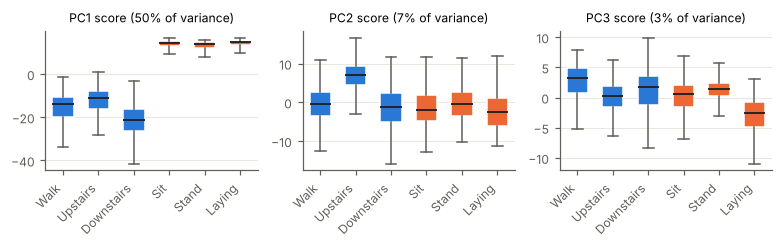

In [20]:
# C16

feat=numpy.array(dedup.keep_)
rows=[]
for j in range(pcs_shown):
    w=pca.components_[j]
    for i in numpy.argsort(-numpy.abs(w))[:top_loadings]:
        rows.append({'PC': f'PC{j+1} ({pca.explained_variance_ratio_[j]:.0%})', 'feature': feat[i], 'loading': round(w[i], 3)})
display(pandas.DataFrame(rows).set_index(['PC', 'feature']))

T_train=pca.transform(Z_train)
T_test=pca.transform(Z_test)
act=y_train_raw.map(activities).to_numpy()
fig, axes=plot.subplots(1, pcs_shown, figsize=(page_width, 2.3), squeeze=False)
for j, ax in enumerate(axes.flat):
    bp=ax.boxplot([T_train[act == a, j] for a in activity_order], widths=0.6, patch_artist=True, showfliers=False,
                  medianprops=dict(color=PALETTE['ink'], lw=1.2),
                  whiskerprops=dict(color=PALETTE['ink2']), capprops=dict(color=PALETTE['ink2']))
    for a, box in zip(activity_order, bp['boxes']):
        box.set(facecolor=PALETTE['blue'] if a in dynamic_activities else PALETTE['orange'], edgecolor='white', linewidth=1)
    ax.set_title(f'PC{j+1} score ({pca.explained_variance_ratio_[j]:.0%} of variance)', fontsize=8)
    ax.set_xticks(range(1, n_classes+1), activity_names, rotation=45, ha='right')
    ax.grid(axis='x', visible=False)
fig.tight_layout()
save_fig(fig, 'pc_scores_by_activity')
plot.show()

PC1 is able to identify 50% of the variance and tracks more the overall movement and pc2 and pc2 are examining more of the AR coefficients and angles of gracity. We are still not able to get a clean differeniation between sitting and standing as those features are mostly representetd by Gravity-Y features that do not appear in at the top. If we drop too many of the components, the model may not longer be able to differentiate between participants who are sitting vs. standing. 

PC2 looks at meanFreq and arCoeff which tracks the frequency of movement. PC3 looks at gravity-X / angle(X,…) which gives us the angle relative to gravity so it tells us if the participant is sitting or standing. All together, the three graphs are able to capture about 98% of the variance of the three best featrues from the sitting / standign group. If we used a lower K, we would loose some of the components that are represented in PC1, 2 and 3.

In [21]:
# C17

def unexplained(Z, T):
    R=Z-pca.inverse_transform(T)
    return (R**2).sum()/((Z-pca.mean_)**2).sum()

print(f'variance not captured by k = {k} components: '
      f'train {unexplained(Z_train, T_train):.1%} | test {unexplained(Z_test, T_test):.1%}')
prep=make_prep(n_components, standardize)
T_train_p=prep.fit_transform(X_train_raw)
T_test_p=prep.transform(X_test_raw)
print(numpy.allclose(numpy.abs(T_train_p), numpy.abs(T_train)), numpy.allclose(numpy.abs(T_test_p), numpy.abs(T_test)))

variance not captured by k = 103 components: train 4.9% | test 6.5%


True True


The 103 components do not capture approximately 4.9% of the traing and 6.5% on the test sets. This is a reduciton of about 1.6% and is expected when the transformers are applied to the unseen participants who have unique quirks on their posture and gait.

- No imputation of the data was required and no outlier handling was required becuase the data did not have any features with missing data and the features were already scaled to -1 and 1.
- There were 21 feature columns that were exactly identical and remvoed, which left 540 features remaining. 
- Z-score standardization was applied only to the training set so that data would not leak into the test set and to make sure that each feature was able to equally contribute and not feature incorrectly dominated the results. 
- PCA retained 103 components which was able to capture 95% of the training variance and that was able to eliminate the muilticollinearity issues. This gave us a smaller dataset that retained the majority of the signals from the orignal set and will be faster to process.

In [22]:
# C18

def squared_distances(X, centres):
    X, centres=numpy.asarray(X, dtype=float), numpy.asarray(centres, dtype=float)
    xx=numpy.einsum('ij,ij->i', X, X)[:, None]
    cc=numpy.einsum('ij,ij->i', centres, centres)[None, :]
    D=xx+cc-2*X@centres.T
    rows, cols_=numpy.where(D <= 1e-12*numpy.maximum(xx+cc, 1))
    if len(rows):
        delta=X[rows]-centres[cols_]
        D[rows, cols_]=numpy.einsum('ij,ij->i', delta, delta)
    return numpy.maximum(D, 0)

def predict_kmeans(X, centroids):
    return squared_distances(X, centroids).argmin(axis=1)

def kmeanx(X, k, max_iterz=300, convergence=1e-5, seed=0):
    X=numpy.asarray(X, dtype=float)
    rng=numpy.random.default_rng(seed)
    centroids=X[rng.choice(len(X), k, replace=False)].copy()
    old_label=None
    history=[]
    converged=False
    for iteration in range(1, max_iterz+1):
        label=predict_kmeans(X, centroids)
        updated=numpy.array([X[label == j].mean(axis=0) if numpy.any(label == j) else X[rng.integers(len(X))]
                             for j in range(k)])
        shift=numpy.linalg.norm(updated-centroids, axis=1).max()
        stable=old_label is not None and numpy.array_equal(label, old_label)
        centroids=updated
        final_label=predict_kmeans(X, centroids)
        objective=float(((X-centroids[final_label])**2).sum())
        history.append(objective)
        if stable or shift < convergence:
            converged=True
            break
        old_label=label
    return dict(centres=centroids, labels=final_label, objective=objective, n_iter=iteration,
                converged=converged, memberships=None)

def best_run(run, starts, seed):
    rng=numpy.random.default_rng(seed)
    results=[run(int(s)) for s in rng.integers(0, 2**32, size=starts)]
    return min(results, key=lambda result: result['objective'])

def best_kmeanx(X, k, max_iterz=300, starts=10, convergence=1e-5, seed=0):
    return best_run(lambda s: kmeanx(X, k, max_iterz, convergence, s), starts, seed)

def update_centre(X, mem_matrix, m=2):
    weights=numpy.asarray(mem_matrix, dtype=float)**m
    return weights.T@numpy.asarray(X, dtype=float)/weights.sum(axis=0)[:, None]

def update_membership(X, centre, m=2):
    distance=numpy.maximum(numpy.sqrt(squared_distances(X, centre)), 1e-10)
    log_weights=-2/(m-1)*numpy.log(distance)
    weights=numpy.exp(log_weights-log_weights.max(axis=1, keepdims=True))
    return weights/weights.sum(axis=1, keepdims=True)

def fcm(X, k, m=2, max_iterz=500, convergence=1e-5, seed=0):
    X=numpy.asarray(X, dtype=float)
    rng=numpy.random.default_rng(seed)
    mem_matrix=rng.random((len(X), k))
    mem_matrix /= mem_matrix.sum(axis=1, keepdims=True)
    converged=False
    for iteration in range(1, max_iterz+1):
        centre=update_centre(X, mem_matrix, m)
        updated=update_membership(X, centre, m)
        change=numpy.abs(updated-mem_matrix).max()
        mem_matrix=updated
        objective=float((mem_matrix**m*squared_distances(X, centre)).sum())
        if change < convergence:
            converged=True
            break
    return dict(centres=centre, labels=mem_matrix.argmax(axis=1), objective=objective, n_iter=iteration,
                converged=converged, memberships=mem_matrix)

def best_fcm(X, k, m=2, max_iterz=500, starts=10, convergence=1e-5, seed=0):
    return best_run(lambda s: fcm(X, k, m, max_iterz, convergence, s), starts, seed)

def contingency_table(y_true, clusters, labels=None, cluster_ids=None):
    table=pandas.crosstab(pandas.Series(numpy.asarray(y_true), name='Activity'),
                          pandas.Series(numpy.asarray(clusters), name='Cluster'))
    return table.reindex(index=labels, columns=cluster_ids, fill_value=0)

def hungarian_mapping(y_true, clusters):
    table=contingency_table(y_true, clusters)
    rows, cols_=linear_sum_assignment(-table.to_numpy())
    return {table.columns[j]: table.index[i] for i, j in zip(rows, cols_)}

def matched_accuracy(y_true, clusters, mapping=None):
    y_true, clusters=numpy.asarray(y_true), numpy.asarray(clusters)
    if mapping is None:
        mapping=hungarian_mapping(y_true, clusters)
    return float(numpy.mean([c in mapping and mapping[c] == t for t, c in zip(y_true, clusters)]))

def clustering_metrics(y_true, clusters, mapping=None):
    return {'ARI': adjusted_rand_score(y_true, clusters), 'NMI': normalized_mutual_info_score(y_true, clusters),
            'matched accuracy': matched_accuracy(y_true, clusters, mapping)}

def partition_coefficient(mem_matrix):
    return float(numpy.mean(numpy.sum(numpy.asarray(mem_matrix)**2, axis=1)))

def mean_max_membership(y_true, mem_matrix):
    return pandas.Series(numpy.asarray(mem_matrix).max(axis=1)).groupby(numpy.asarray(y_true)).mean()

PCA / k=6 / K-means converged: True iterations: 10


PCA / k=6 / FCM converged: True iterations: 71


ARI     NMI  matched accuracy  \
space k method  split                                     
PCA   6 K-means train  0.4227  0.5607            0.5411   
                test   0.4428  0.5910            0.5405   
        FCM     train  0.2916  0.4605            0.4378   
                test   0.3200  0.4828            0.4829   

                       split-optimal accuracy  partition coefficient  \
space k method  split                                                  
PCA   6 K-means train                  0.5411                    NaN   
                test                   0.5738                    NaN   
        FCM     train                  0.4378                 0.2383   
                test                   0.4829                 0.2370   

                       fit seconds  test predict seconds  
space k method  split                                     
PCA   6 K-means train       2.5187                0.0013  
                test        2.5187                0.0013  
        FCM     train       3.7524                0.0016  
                test        3.7524                0.0016

,iterations,converged,objective,min centre distance,train cluster sizes,fit seconds (all restarts),test predict seconds
run,,,,,,,
PCA / k=6 / K-means,10,True,1.591184e+06,9.168408e+00,"[239, 1921, 1726, 1321, 1197, 948]",2.518718,0.001301
PCA / k=6 / FCM,71,True,5.313968e+05,1.455246e-08,"[1730, 1507, 0, 2337, 1778, 0]",3.752419,0.001583


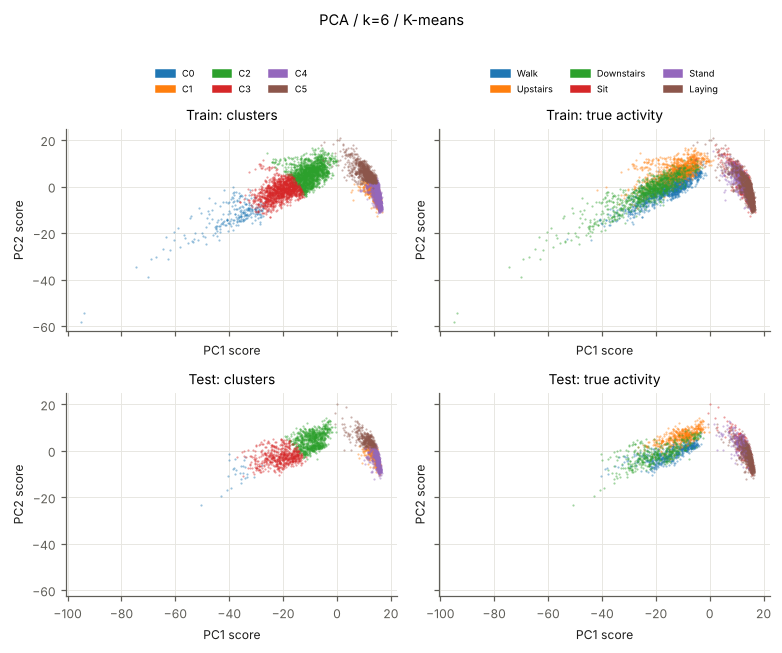

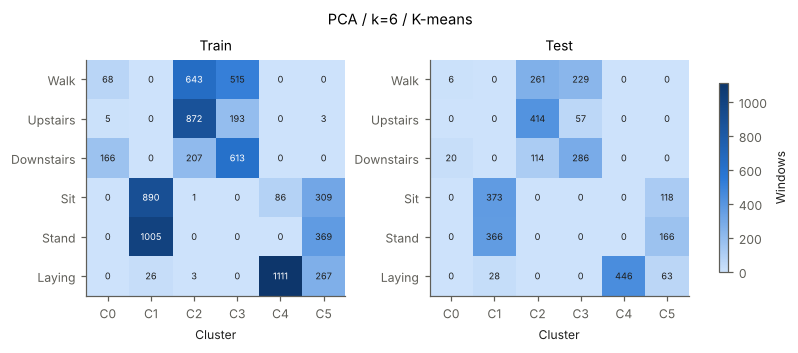

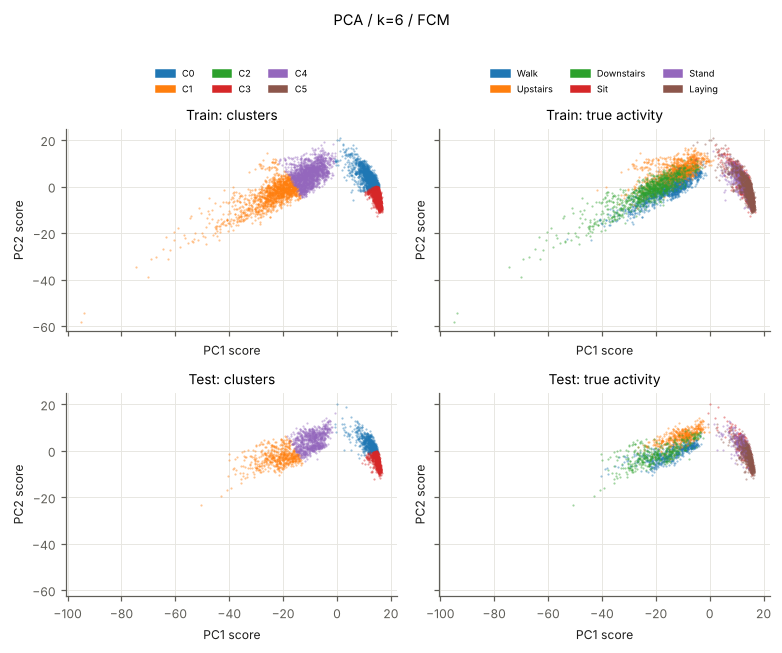

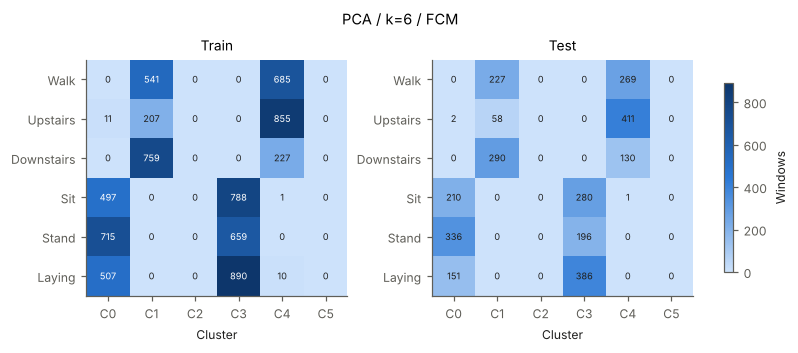

In [23]:
# C19

V_train, V_test=T_train[:, :2], T_test[:, :2]
runs, cluster_rows, diagnostic_rows, membership_rows={}, [], [], []

def run_pair(space, X_tr, X_te, k, y_tr, y_te, labels, names):
    for method, fit in (('K-means', best_kmeanx), ('FCM', best_fcm)):
        key=f'{space} / k={k} / {method}'
        with threadpool_limits(limits=1):
            start=perf_counter()
            result=fit(X_tr, k, max_iterz=max_iterz, starts=starts, convergence=convergence, seed=seed,
                       **({'m': m} if method == 'FCM' else {}))
            fit_seconds=perf_counter()-start
            start=perf_counter()
            mem_test=update_membership(X_te, result['centres'], m) if method == 'FCM' else None
            test_labels=mem_test.argmax(axis=1) if mem_test is not None else predict_kmeans(X_te, result['centres'])
            predict_seconds=perf_counter()-start
        mapping=hungarian_mapping(y_tr, result['labels'])
        runs[key]=dict(result=result, train=result['labels'], test=test_labels, mem_train=result['memberships'],
                       mem_test=mem_test, ytrain=y_tr, ytest=y_te, labels=labels, names=names, k=k, mapping=mapping)
        distances=squared_distances(result['centres'], result['centres'])
        numpy.fill_diagonal(distances, numpy.inf)
        diagnostic_rows.append({'run': key, 'iterations': result['n_iter'], 'converged': result['converged'],
                                'objective': result['objective'], 'min centre distance': numpy.sqrt(distances.min()),
                                'train cluster sizes': numpy.bincount(result['labels'], minlength=k).tolist(),
                                'fit seconds (all restarts)': fit_seconds, 'test predict seconds': predict_seconds})
        for split, truth, pred, mem in (('train', y_tr, result['labels'], result['memberships']),
                                        ('test', y_te, test_labels, mem_test)):
            cluster_rows.append({'space': space, 'k': k, 'method': method, 'split': split,
                                 **clustering_metrics(truth, pred, mapping),
                                 'split-optimal accuracy': matched_accuracy(truth, pred),
                                 'partition coefficient': partition_coefficient(mem) if mem is not None else numpy.nan,
                                 'fit seconds': fit_seconds, 'test predict seconds': predict_seconds})
            if mem is not None:
                means=mean_max_membership(truth, mem)
                for label, name in zip(labels, names):
                    membership_rows.append({'run': key, 'split': split, 'class': name, 'mean max membership': means.loc[label]})
        print(key, 'converged:', result['converged'], 'iterations:', result['n_iter'])

def cluster_metrics(k=None):
    frame=pandas.DataFrame(cluster_rows)
    if k is not None:
        frame=frame.loc[frame['k'] == k]
    return frame.set_index(['space', 'k', 'method', 'split'])

def scatter_run(key, filename):
    run=runs[key]
    colors=plot.get_cmap('tab10').colors
    fig, axes=plot.subplots(2, 2, figsize=(page_width, 5.8), sharex=True, sharey=True)
    for row, (split, V, truth) in enumerate((('train', V_train, run['ytrain']), ('test', V_test, run['ytest']))):
        for col, values in enumerate((run[split], truth)):
            ax=axes[row, col]
            ids=range(run['k']) if col == 0 else run['labels']
            names=[f'C{i}' for i in ids] if col == 0 else run['names']
            for j, label in enumerate(ids):
                mask=values == label
                ax.scatter(V[mask, 0], V[mask, 1], s=2, alpha=.45, color=colors[j], linewidths=0, rasterized=True)
            ax.set_title(f"{split.title()}: {'clusters' if col == 0 else 'true activity'}")
            if row == 0:
                ax.legend([Patch(color=colors[j]) for j in range(len(names))], names, ncol=3, fontsize=6,
                          loc='lower center', bbox_to_anchor=(.5, 1.13))
            ax.set_xlabel('PC1 score')
            ax.set_ylabel('PC2 score')
    fig.suptitle(key, y=1.01)
    fig.tight_layout()
    save_fig(fig, filename)
    plot.show()

def heatmap_run(key, filename):
    run=runs[key]
    tables=[contingency_table(run[f'y{split}'], run[split], run['labels'], range(run['k'])) for split in ('train', 'test')]
    fig, axes=plot.subplots(1, 2, figsize=(page_width, 3.1), constrained_layout=True)
    vmax=max(table.to_numpy().max() for table in tables)
    for ax, split, table in zip(axes, ('Train', 'Test'), tables):
        values=table.to_numpy()
        im=ax.imshow(values, aspect='auto', cmap=SEQUENTIAL, vmin=0, vmax=vmax)
        ax.set_yticks(range(len(run['labels'])), run['names'])
        ax.set_xticks(range(run['k']), [f'C{i}' for i in range(run['k'])])
        ax.set_xlabel('Cluster')
        ax.set_title(split)
        ax.grid(False)
        for (i, j), value in numpy.ndenumerate(values):
            ax.text(j, i, str(value), ha='center', va='center', fontsize=6,
                    color='white' if value > .55*vmax else PALETTE['ink'])
    fig.colorbar(im, ax=axes, label='Windows', shrink=.8)
    fig.suptitle(key)
    save_fig(fig, filename)
    plot.show()

def membership_run(key, filename):
    run=runs[key]
    fig, axes=plot.subplots(1, 2, figsize=(page_width, 2.9), sharey=True)
    for ax, split in zip(axes, ('train', 'test')):
        mem, truth=run[f'mem_{split}'], run[f'y{split}']
        bp=ax.boxplot([mem.max(axis=1)[truth == label] for label in run['labels']], widths=.6, patch_artist=True,
                      showfliers=False, medianprops=dict(color=PALETTE['ink']))
        for box in bp['boxes']:
            box.set(facecolor=PALETTE['blue'], alpha=.65)
        ax.axhline(1/run['k'], color=PALETTE['ink2'], ls='--', lw=.8)
        ax.set_xticks(range(1, len(run['names'])+1), run['names'], rotation=35, ha='right')
        ax.set_title(split.title())
        ax.set_ylim(0, 1.02)
        ax.grid(axis='x', visible=False)
        ax.set_ylabel('Maximum FCM membership')
    fig.suptitle(key, fontsize=9)
    fig.tight_layout()
    save_fig(fig, filename)
    plot.show()

class_ids=list(range(n_classes))
run_pair('PCA', T_train, T_test, activity_clusters, y_train, y_test, class_ids, activity_names)
display(cluster_metrics(activity_clusters).round(4))
display(pandas.DataFrame(diagnostic_rows).set_index('run'))
for method, stem in (('K-means', 'kmeans'), ('FCM', 'fcm')):
    key=f'PCA / k={activity_clusters} / {method}'
    scatter_run(key, f'pca_{stem}_scatter')
    heatmap_run(key, f'pca_{stem}_contingency')

The most obvious issue is that Fuzzy C-Means couldn't identify six clusters fromthe data; there are two clusters that are completely empty. This means that multiple centroids ended up with the same coordinates and couldn't be differentiated. K-Means was able to identify six individual clusers. On this dataset, K-Means was able to perform better than FCM on the test set. FCM also has a low partition coefficient which indicates there is a lot of uncertenty regarding which cluster data was assigned to. Because the the sitting and standing features are difficult to differentiate, the clustering arbitarily split the activities that were dynamic and lowers the overall accuracy. The PC1-PC2 plots show the split between the dynamic and static activities and only captures about 57% of the variance vs the actual 95%.

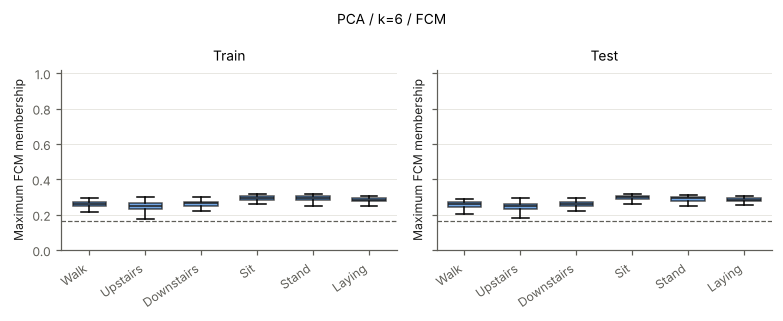

In [24]:
# C20

membership_run(f'PCA / k={activity_clusters} / FCM', 'pca_fcm_memberships')

K-means shows much better alignment that Fuzzy C-means with the true labels. Looking at the test split, k-means has a high adjusted rand index, normalized mutual information and matched accuracy score. The partition coefficient for fuzzy c-means is low for both the training and test sets; this shows that the algorythm is highly uncertain about the feature memberships. AS noted previously, FCM was not able to find six groups, and produced two empty clusters; k-means had a minimum center distance of 9.16 and was able to locate all six clusters. The hard labels aren't helpful in this case where the memberships are nearly tied; the labels can only be used to arbitrarily seperate two points that are tied but that doesn't carry any useful information.

PCA / k=2 / K-means converged: True iterations: 6


PCA / k=2 / FCM converged: True iterations: 17


ARI     NMI  matched accuracy  \
space k method  split                                     
PCA   2 K-means train  0.9891  0.9727            0.9973   
                test   0.9973  0.9925            0.9993   
        FCM     train  0.9881  0.9704            0.9970   
                test   0.9959  0.9885            0.9990   

                       split-optimal accuracy  partition coefficient  \
space k method  split                                                  
PCA   2 K-means train                  0.9973                    NaN   
                test                   0.9993                    NaN   
        FCM     train                  0.9970                 0.7148   
                test                   0.9990                 0.7111   

                       fit seconds  test predict seconds  
space k method  split                                     
PCA   2 K-means train       0.3788                0.0011  
                test        0.3788                0.0011  
        FCM     train       0.8234                0.0015  
                test        0.8234                0.0015

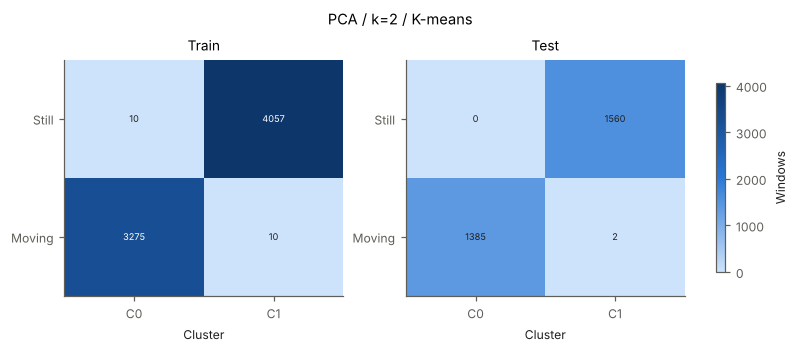

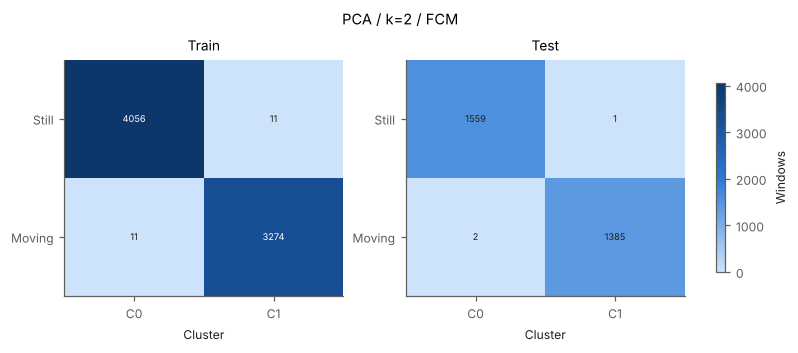

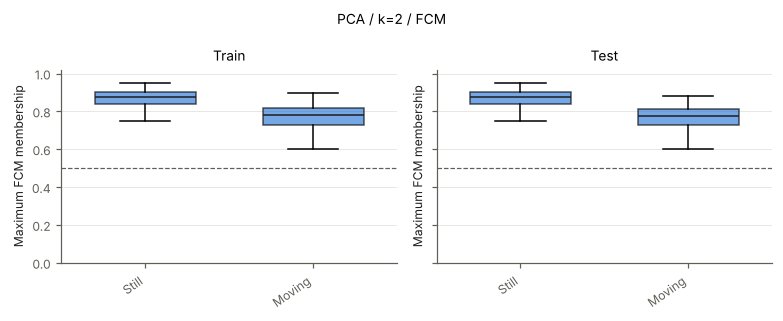

In [25]:
# C21

moving_train=numpy.isin(y_train_raw, moving_ids).astype(int)
moving_test=numpy.isin(y_test_raw, moving_ids).astype(int)
run_pair('PCA', T_train, T_test, movement_clusters, moving_train, moving_test, [0, 1], ['Still', 'Moving'])
display(cluster_metrics(movement_clusters).round(4))
for method, stem in (('K-means', 'kmeans'), ('FCM', 'fcm')):
    heatmap_run(f'PCA / k={movement_clusters} / {method}', f'moving_still_{stem}_contingency')
membership_run(f'PCA / k={movement_clusters} / FCM', 'moving_still_fcm_memberships')

K=2 is able to better distinguish between moving vs skill much better than k=6 can distinguish between the individual activities. K-means on the test set gets an almost perfect accuracy of .99 and an ARI of 0.9973 which is much better than the k-means results of k=6 that had an accuracy of 0.54 and ARI if 0.4428. FCM did well with K=2 but not at k=6' the k=2 accuracy was .09885 and the ARI was 0.9959 but with k=6 FCM wasn't even able to identify six clusters. The contingecy tables for k-means at k=2 have an almost perfect diagonal matrix with very limited cusfusion. 

The geometry shows almost perfect performance at k=2 shows that the main division in the dataset is the seperation of static and dynamic movement. These results indicate that we can't choose k=6 simply because there are six ground truth labels becasue those lables aren't consistant with the actual grouping.

No PCA / k=6 / K-means converged: True iterations: 11


No PCA / k=6 / FCM converged: True iterations: 47


ARI     NMI  matched accuracy  \
space  k method  split                                     
PCA    6 K-means train  0.4227  0.5607            0.5411   
                 test   0.4428  0.5910            0.5405   
         FCM     train  0.2916  0.4605            0.4378   
                 test   0.3200  0.4828            0.4829   
No PCA 6 K-means train  0.4229  0.5610            0.5423   
                 test   0.4417  0.5902            0.5548   
         FCM     train  0.2912  0.4602            0.4369   
                 test   0.3178  0.4810            0.4801   

                        split-optimal accuracy  partition coefficient  \
space  k method  split                                                  
PCA    6 K-means train                  0.5411                    NaN   
                 test                   0.5738                    NaN   
         FCM     train                  0.4378                 0.2383   
                 test                   0.4829                 0.2370   
No PCA 6 K-means train                  0.5423                    NaN   
                 test                   0.5728                    NaN   
         FCM     train                  0.4369                 0.2329   
                 test                   0.4801                 0.2308   

                        fit seconds  test predict seconds  
space  k method  split                                     
PCA    6 K-means train       2.5187                0.0013  
                 test        2.5187                0.0013  
         FCM     train       3.7524                0.0016  
                 test        3.7524                0.0016  
No PCA 6 K-means train      21.2874                0.0078  
                 test       21.2874                0.0078  
         FCM     train      18.1684                0.0067  
                 test       18.1684                0.0067

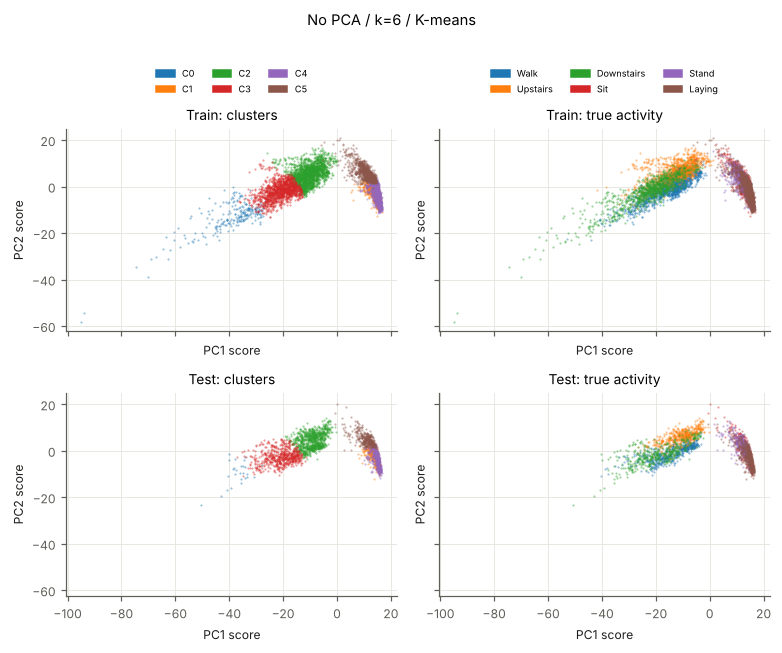

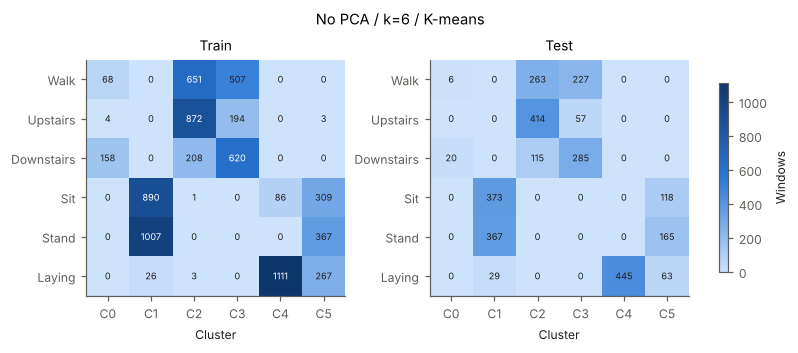

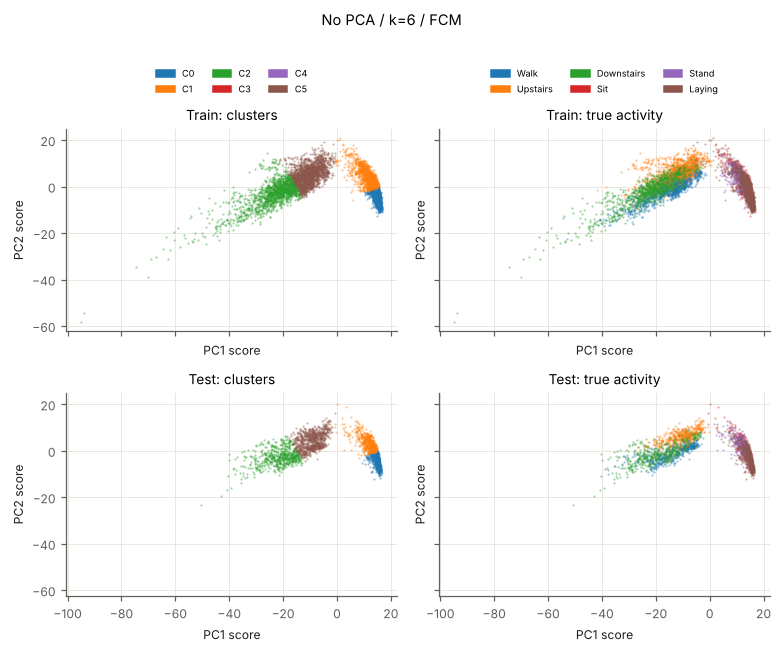

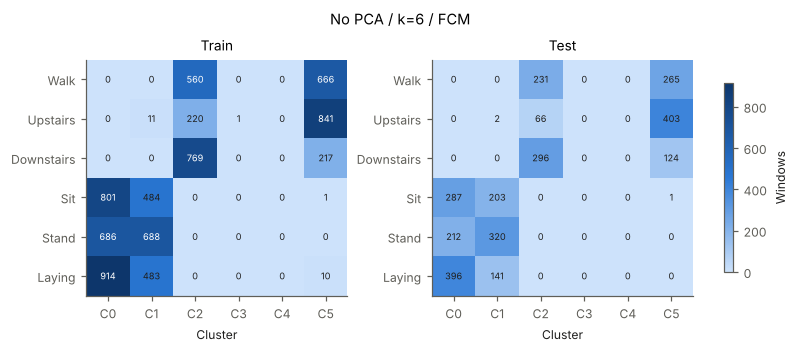

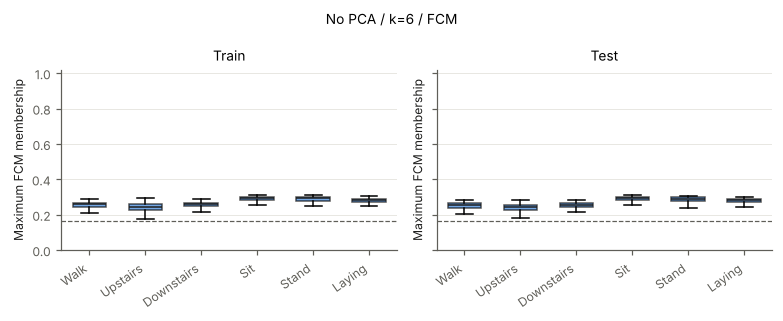

In [26]:
# C22

run_pair('No PCA', Z_train, Z_test, activity_clusters, y_train, y_test, class_ids, activity_names)
display(cluster_metrics(activity_clusters).round(4))
for method, stem in (('K-means', 'kmeans'), ('FCM', 'fcm')):
    key=f'No PCA / k={activity_clusters} / {method}'
    scatter_run(key, f'no_pca_{stem}_scatter')
    heatmap_run(key, f'no_pca_{stem}_contingency')
membership_run(f'No PCA / k={activity_clusters} / FCM', 'no_pca_fcm_memberships')

The results are pretty much the same for both the PCA and no-pca models. The k-means accuracy was 0.5405 for the PCA model and 0.5548 for the no-pca model. The FCM results are also almost identical in the PCA and no-pca models so that tells us that there is a fair amount of ambiguity even with the full 540 feature set. If we don't perform PCA that increase the computational overhead significantly; the time for k-means is 0.733 seconds when PCA is performed and 4.449 seconds when it's not. 

Retained variance is an acceptable proxy for activity seperation. It's obvious from the results that the 5% of the variance that was disgarded didn't contain any useful information. 

If order to justify changing the placeholder for K=2 we would need to determine if retaining less variance would still produce the same results and give us more improvement in speed by using less computational overhead.

In [27]:
# C23

display(cluster_metrics().round(4))
display(pandas.DataFrame(diagnostic_rows).set_index('run'))
display(pandas.DataFrame(membership_rows).pivot(index=['run', 'class'], columns='split',
                                                values='mean max membership').round(4))

ARI     NMI  matched accuracy  \
space  k method  split                                     
PCA    6 K-means train  0.4227  0.5607            0.5411   
                 test   0.4428  0.5910            0.5405   
         FCM     train  0.2916  0.4605            0.4378   
                 test   0.3200  0.4828            0.4829   
       2 K-means train  0.9891  0.9727            0.9973   
                 test   0.9973  0.9925            0.9993   
         FCM     train  0.9881  0.9704            0.9970   
                 test   0.9959  0.9885            0.9990   
No PCA 6 K-means train  0.4229  0.5610            0.5423   
                 test   0.4417  0.5902            0.5548   
         FCM     train  0.2912  0.4602            0.4369   
                 test   0.3178  0.4810            0.4801   

                        split-optimal accuracy  partition coefficient  \
space  k method  split                                                  
PCA    6 K-means train                  0.5411                    NaN   
                 test                   0.5738                    NaN   
         FCM     train                  0.4378                 0.2383   
                 test                   0.4829                 0.2370   
       2 K-means train                  0.9973                    NaN   
                 test                   0.9993                    NaN   
         FCM     train                  0.9970                 0.7148   
                 test                   0.9990                 0.7111   
No PCA 6 K-means train                  0.5423                    NaN   
                 test                   0.5728                    NaN   
         FCM     train                  0.4369                 0.2329   
                 test                   0.4801                 0.2308   

                        fit seconds  test predict seconds  
space  k method  split                                     
PCA    6 K-means train       2.5187                0.0013  
                 test        2.5187                0.0013  
         FCM     train       3.7524                0.0016  
                 test        3.7524                0.0016  
       2 K-means train       0.3788                0.0011  
                 test        0.3788                0.0011  
         FCM     train       0.8234                0.0015  
                 test        0.8234                0.0015  
No PCA 6 K-means train      21.2874                0.0078  
                 test       21.2874                0.0078  
         FCM     train      18.1684                0.0067  
                 test       18.1684                0.0067

,iterations,converged,objective,min centre distance,train cluster sizes,fit seconds (all restarts),test predict seconds
run,,,,,,,
PCA / k=6 / K-means,10,True,1.591184e+06,9.168408e+00,"[239, 1921, 1726, 1321, 1197, 948]",2.518718,0.001301
PCA / k=6 / FCM,71,True,5.313968e+05,1.455246e-08,"[1730, 1507, 0, 2337, 1778, 0]",3.752419,0.001583
PCA / k=2 / K-means,6,True,2.091786e+06,3.042966e+01,"[3285, 4067]",0.378832,0.001138
PCA / k=2 / FCM,17,True,1.594190e+06,2.780266e+01,"[4067, 3285]",0.823376,0.001496
No PCA / k=6 / K-means,11,True,1.786379e+06,9.173764e+00,"[230, 1923, 1735, 1321, 1197, 946]",21.287428,0.007799
No PCA / k=6 / FCM,47,True,5.749925e+05,2.380660e-07,"[2401, 1666, 1549, 1, 0, 1735]",18.168392,0.006748


split                            test   train
run                class                     
No PCA / k=6 / FCM Downstairs  0.2536  0.2561
                   Laying      0.2767  0.2748
                   Sit         0.2877  0.2857
                   Stand       0.2835  0.2860
                   Upstairs    0.2409  0.2431
                   Walk        0.2513  0.2538
PCA / k=2 / FCM    Moving      0.7615  0.7661
                   Still       0.8614  0.8585
PCA / k=6 / FCM    Downstairs  0.2597  0.2614
                   Laying      0.2817  0.2788
                   Sit         0.2920  0.2899
                   Stand       0.2881  0.2902
                   Upstairs    0.2454  0.2468
                   Walk        0.2569  0.2581

The clustering performs well to the unseen particapents. On pretty much all of the models, the performance on the test and split sets are almost identical. In the PCA model, K=6 k-means model the training accuracy was 0.5411 and the test set had an accuracy of 0.5405.

None of the activity features changed significantly between the training and test sets. The FCM memberships for k=6 on the PCA model are vary by less than 0.003.

For Hungarian mapping it transferrs well tot he test data. For the PCA model the K=6 only had a minor improvement in accuracy; up to 0.5738 from 0.5405 (roughly 3%) and all of the FCM and K=2 models those results stay the same.

- When we tried to have the model identify six seperate activities, k-means did a much better job than FCM which collapsed clusters and produced two empty ones. FCM also have us a high lvels of membership ambiguity that resulted in a partition coefficent of 0.23. 
- The reasons for the issues with producing six clusters has to do with the inability to distinguish exact activies beyond general sitting and standing. When we used a k value of 2, there was higher accuracy becuase the dataset could be clearly borken in to two groups (sitting and standing).
- When we disgarded 5% of the variance during PCA, we had a proxy for unsupervised clustering because the disgaurded values didn't carry any additional information.

In [28]:
# C24

def add_intercept(X):
    return numpy.hstack([numpy.ones((X.shape[0], 1)), numpy.asarray(X, dtype=float)])

def sigmoid(z):
    z=numpy.clip(z, -z_clip, z_clip)
    return 1.0/(1.0+numpy.exp(-z))

def one_hot(y, k):
    return numpy.eye(k)[numpy.asarray(y, dtype=int)]

def no_intercept(theta):
    weights=numpy.array(theta, dtype=float, copy=True)
    weights[0]=0.0
    return weights

def cost(X, Y, theta, lam=0.0):
    m_rows=len(X)
    h=numpy.clip(sigmoid(X@theta), eps, 1.0-eps)
    cross_entropy=-numpy.sum(Y*numpy.log(h)+(1-Y)*numpy.log(1-h), axis=0)/m_rows
    penalty=lam/(2.0*m_rows)*numpy.sum(no_intercept(theta)**2, axis=0)
    return cross_entropy+penalty

def gradient(X, Y, theta, lam=0.0):
    m_rows=len(X)
    return X.T@(sigmoid(X@theta)-Y)/m_rows+lam/m_rows*no_intercept(theta)

def step_size(X, lam=0.0):
    X=numpy.asarray(X, dtype=float)
    return 1.0/(numpy.linalg.eigvalsh(X.T@X/len(X)).max()/4.0+lam/len(X))

def gradient_descent(X, Y, alpha=None, iters=n_iters, lam=0.0, tol=tol):
    X, Y=numpy.asarray(X, dtype=float), numpy.asarray(Y, dtype=float)
    if Y.ndim == 1:
        Y=Y[:, None]
    alpha=step_size(X, lam) if alpha is None else float(alpha)
    m_rows=len(X)
    theta=numpy.zeros((X.shape[1], Y.shape[1]))
    J_history=[]
    converged=False
    for iteration in range(1, iters+1):
        h=sigmoid(X@theta)
        hc=numpy.clip(h, eps, 1.0-eps)
        J_history.append(-numpy.sum(Y*numpy.log(hc)+(1-Y)*numpy.log(1-hc), axis=0)/m_rows
                         +lam/(2.0*m_rows)*numpy.sum(no_intercept(theta)**2, axis=0))
        grad=X.T@(h-Y)/m_rows+lam/m_rows*no_intercept(theta)
        largest=numpy.abs(grad).max(axis=0)
        if largest.max() < tol:
            converged=True
            break
        theta -= alpha*grad
    return dict(theta=theta, J_history=numpy.array(J_history), n_iter=iteration, converged=converged,
                final_gradient=largest, alpha=alpha)

def predict_proba(X, theta):
    return sigmoid(numpy.asarray(X, dtype=float)@theta)

def predict(X, theta):
    return predict_proba(X, theta).argmax(axis=1)

def confusion(y_true, y_pred, k):
    table=numpy.zeros((k, k), dtype=int)
    numpy.add.at(table, (numpy.asarray(y_true, dtype=int), numpy.asarray(y_pred, dtype=int)), 1)
    return table

def per_class(table, names=None):
    table=numpy.asarray(table, dtype=float)
    tp=numpy.diag(table)
    with numpy.errstate(divide='ignore', invalid='ignore'):
        precision=numpy.where(table.sum(axis=0) > 0, tp/table.sum(axis=0), 0.0)
        recall=numpy.where(table.sum(axis=1) > 0, tp/table.sum(axis=1), 0.0)
        f1=numpy.where(precision+recall > 0, 2*precision*recall/(precision+recall), 0.0)
    return pandas.DataFrame({'precision': precision, 'recall': recall, 'F1': f1,
                             'support': table.sum(axis=1).astype(int)}, index=names)

def metrics(y_true, y_pred, k):
    table=confusion(y_true, y_pred, k)
    pc=per_class(table)
    return {'accuracy': float(numpy.trace(table)/table.sum()), 'macro precision': float(pc['precision'].mean()),
            'macro recall': float(pc['recall'].mean()), 'macro F1': float(pc['F1'].mean())}

def ova_agreement(P, threshold=threshold):
    votes=(numpy.asarray(P) >= threshold).sum(axis=1)
    return {'no classifier >= 0.5': float(numpy.mean(votes == 0)), 'several classifiers >= 0.5': float(numpy.mean(votes > 1))}

def penalty_value(theta, lam, penalty, m_rows):
    weights=no_intercept(theta)
    if penalty == 'l2':
        return lam/(2.0*m_rows)*numpy.sum(weights**2, axis=0)
    return lam/m_rows*numpy.sum(numpy.abs(weights), axis=0)

def shrink(theta, step, penalty):
    out=theta.copy()
    if penalty == 'l2':
        out[1:]=theta[1:]/(1.0+step)
    else:
        out[1:]=numpy.sign(theta[1:])*numpy.maximum(numpy.abs(theta[1:])-step, 0.0)
    return out

def objective(X, Y, theta, lam=0.0, penalty='l2'):
    return cost(X, Y, theta, 0.0)+penalty_value(theta, lam, penalty, len(X))

def fit_penalized(X, Y, lam, penalty='l2', alpha=None, iters=cv_iters, tol=cv_tol, theta0=None, accelerated=True):
    X, Y=numpy.asarray(X, dtype=float), numpy.asarray(Y, dtype=float)
    if Y.ndim == 1:
        Y=Y[:, None]
    m_rows=len(X)
    alpha=step_size(X) if alpha is None else float(alpha)
    theta=numpy.zeros((X.shape[1], Y.shape[1])) if theta0 is None else numpy.array(theta0, dtype=float)
    point, t=theta.copy(), 1.0
    converged=False
    for iteration in range(1, iters+1):
        grad=X.T@(sigmoid(X@point)-Y)/m_rows
        new=shrink(point-alpha*grad, alpha*lam/m_rows, penalty)
        change=numpy.abs(new-point).max(axis=0)/alpha
        if accelerated:
            if numpy.sum((point-new)*(new-theta)) > 0:
                t=1.0
            t_next=(1.0+numpy.sqrt(1.0+4.0*t*t))/2.0
            point=new+(t-1.0)/t_next*(new-theta)
            t=t_next
        else:
            point=new
        theta=new
        if change.max() < tol:
            converged=True
            break
    return dict(theta=theta, n_iter=iteration, converged=converged, final_gradient=change, alpha=alpha)

PCA (scaled scores): alpha=4, 5000 steps, converged=False, fit 12.2 s


,final cost,largest |gradient|,below tol=0.0001
model: class vs rest,,,
Walk,0.001910,0.000172,False
Upstairs,0.012863,0.000238,False
Downstairs,0.001476,0.000154,False
Sit,0.067136,0.000198,False
Stand,0.051754,0.000173,False
Laying,0.000195,0.000051,True


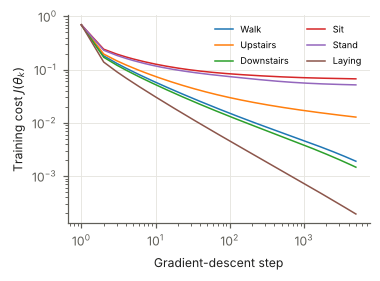

In [29]:
# C25

score_std=T_train.std(axis=0)
S_train, S_test=T_train/score_std, T_test/score_std
A_train, A_test=add_intercept(S_train), add_intercept(S_test)
Y_train=one_hot(y_train, n_classes)
fits, summary_rows={}, []

def fit_baseline(name, X_tr, X_te):
    A_tr, A_te=add_intercept(X_tr), add_intercept(X_te)
    start=perf_counter()
    result=gradient_descent(A_tr, Y_train, alpha=alpha, iters=n_iters, lam=0.0, tol=tol)
    fit_seconds=perf_counter()-start
    P_tr, P_te=predict_proba(A_tr, result['theta']), predict_proba(A_te, result['theta'])
    fits[name]=dict(result=result, P_train=P_tr, P_test=P_te, pred_train=P_tr.argmax(axis=1),
                    pred_test=P_te.argmax(axis=1), fit_seconds=fit_seconds)
    for split, truth in (('train', y_train), ('test', y_test)):
        summary_rows.append({'model': name, 'split': split, **metrics(truth, fits[name][f'pred_{split}'], n_classes),
                             **ova_agreement(fits[name][f'P_{split}']), 'features': X_tr.shape[1],
                             'fit seconds': fit_seconds})
    print(f"{name}: alpha={result['alpha']:.4g}, {result['n_iter']} steps, converged={result['converged']}, fit {fit_seconds:.1f} s")

def baseline_summary(names=None):
    frame=pandas.DataFrame(summary_rows).set_index(['model', 'split'])
    return frame if names is None else frame.loc[names]

def convergence_table(name):
    result=fits[name]['result']
    return pandas.DataFrame({'final cost': result['J_history'][-1], 'largest |gradient|': result['final_gradient'],
                             f'below tol={tol}': result['final_gradient'] < tol},
                            index=pandas.Index(activity_names, name='model: class vs rest'))

def plot_confusion_pair(name, filename):
    fig, axes=plot.subplots(1, 2, figsize=(page_width, 3.0), constrained_layout=True)
    for ax, split, truth in zip(axes, ('train', 'test'), (y_train, y_test)):
        table=confusion(truth, fits[name][f'pred_{split}'], n_classes)
        share=table/table.sum(axis=1, keepdims=True)
        im=ax.imshow(share, cmap=SEQUENTIAL, vmin=0, vmax=1)
        for (i, j), count in numpy.ndenumerate(table):
            ax.text(j, i, str(count), ha='center', va='center', fontsize=6,
                    color='white' if share[i, j] > .55 else PALETTE['ink'])
        ax.set_xticks(range(n_classes), activity_names, rotation=35, ha='right')
        ax.set_yticks(range(n_classes), activity_names)
        ax.set_xlabel('Predicted')
        ax.set_ylabel('True')
        ax.grid(False)
        ax.set_title(f'{split.title()} (accuracy {numpy.trace(table)/table.sum():.3f})')
    fig.colorbar(im, ax=axes, label='Share of true class (row)', shrink=.8)
    fig.suptitle(name)
    save_fig(fig, filename)
    plot.show()

def class_table(name):
    return pandas.concat({split: per_class(confusion(truth, fits[name][f'pred_{split}'], n_classes), activity_names)
                          for split, truth in (('train', y_train), ('test', y_test))}, axis=1)

baseline='PCA (scaled scores)'
fit_baseline(baseline, S_train, S_test)
display(convergence_table(baseline).round(6))
history=fits[baseline]['result']['J_history']
steps=numpy.arange(1, len(history)+1)
colors=plot.get_cmap('tab10').colors
fig, ax=plot.subplots(figsize=(col_width, 2.6))
for j, label in enumerate(activity_names):
    ax.plot(steps, history[:, j], color=colors[j], lw=1, label=label)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Gradient-descent step')
ax.set_ylabel(r'Training cost $J(\theta_k)$')
ax.legend(ncol=2, fontsize=6)
fig.tight_layout()
save_fig(fig, 'baseline_cost_curves')
plot.show()

The model representing laying down was able to achieve the lowest training cost which also means that it was the easiest activity to classify. The models representing sitting and standing were the most difficult and also had the highest training costs (0.067 for sitting and 0.052 for standing/statu). The only model that was able to achieve the gradient tolerence of .0001 withing 5000 iterations was laying down; both the sitting and standing models were not able to converge. The walking and downstairs models failed to converge without a penalty (y=0) which means the probabilities keep moving toward either 0 or 1.

Because the model didn't converge on classes that should be easy to seperate the dataset needs to be regularized with L1 and L2 penalities so that the probabilities don't continue to grow unchecked. This would force the models to converge and prevent overfitting.

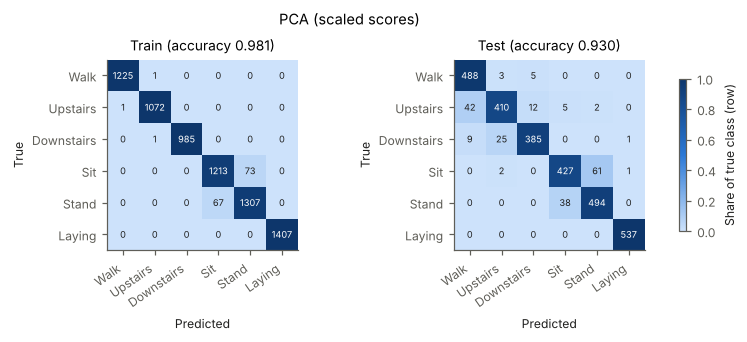

train                              test                        
           precision  recall      F1 support precision  recall      F1 support
Walk          0.9992  0.9992  0.9992    1226    0.9054  0.9839  0.9430     496
Upstairs      0.9981  0.9991  0.9986    1073    0.9318  0.8705  0.9001     471
Downstairs    1.0000  0.9990  0.9995     986    0.9577  0.9167  0.9367     420
Sit           0.9477  0.9432  0.9454    1286    0.9085  0.8697  0.8887     491
Stand         0.9471  0.9512  0.9492    1374    0.8869  0.9286  0.9073     532
Laying        1.0000  1.0000  1.0000    1407    0.9963  1.0000  0.9981     537

accuracy  macro precision  macro recall  macro F1  \
model               split                                                      
PCA (scaled scores) train    0.9805           0.9820        0.9820     0.982   
                    test     0.9301           0.9311        0.9282     0.929   

                           no classifier >= 0.5  several classifiers >= 0.5  \
model               split                                                     
PCA (scaled scores) train                0.0146                       0.009   
                    test                 0.0601                       0.038   

                           features  fit seconds  
model               split                         
PCA (scaled scores) train       103      12.1945  
                    test        103      12.1945

In [30]:
# C26

plot_confusion_pair(baseline, 'baseline_confusion')
display(class_table(baseline).round(4))
display(baseline_summary([baseline]).round(4))

The main confusion seems to occur between the sit and stand classes (there is a 86.97% test recall for Sit and 92.86% for Stand) indicating that both of those features are often misclassified as one another with sit being confused for stand more often. We can see that there is also a little confusion in the dynamic features like Upstairs moving into Walk and Downstairs. These are the same pairs that were merged previously.

There isn't much confusion with features between the dynamic and static classes.

Using supervised learning showed an advantage over clustering with the accurance inproving from about 0.54 accuracy after matching clusers to labels compaired to 0.9301 (plain accuract) for the PCA scaled logestic regression baseline. 

Looking at the test set, the all vs. one rule didn't give us a clean result a little less than 10% of the time.

PCA (unscaled scores): alpha=0.01487, 5000 steps, converged=False, fit 12.7 s


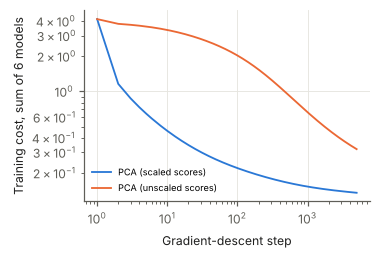

accuracy  macro precision  macro recall  \
model                 split                                            
PCA (scaled scores)   train    0.9805           0.9820        0.9820   
                      test     0.9301           0.9311        0.9282   
PCA (unscaled scores) train    0.9640           0.9659        0.9657   
                      test     0.9348           0.9362        0.9336   

                             macro F1  no classifier >= 0.5  \
model                 split                                   
PCA (scaled scores)   train    0.9820                0.0146   
                      test     0.9290                0.0601   
PCA (unscaled scores) train    0.9658                0.0169   
                      test     0.9342                0.0424   

                             several classifiers >= 0.5  features  fit seconds  
model                 split                                                     
PCA (scaled scores)   train                      0.0090       103      12.1945  
                      test                       0.0380       103      12.1945  
PCA (unscaled scores) train                      0.0267       103      12.6820  
                      test                       0.0526       103      12.6820

gradient descent accuracy  scikit-learn accuracy  \
model               split                                                     
PCA (scaled scores) train                     0.9805                 0.9819   
                    test                      0.9301                 0.9287   

                           same prediction  
model               split                   
PCA (scaled scores) train           0.9951  
                    test            0.9698

In [31]:
#testing / validation

reference_rows=[]
def sklearn_reference(name, X_tr, X_te):
    model=OneVsRestClassifier(LogisticRegression(C=numpy.inf, max_iter=10000, tol=1e-8)).fit(X_tr, y_train)
    for split, truth, ours, ref in (('train', y_train, fits[name]['pred_train'], model.predict(X_tr)),
                                    ('test', y_test, fits[name]['pred_test'], model.predict(X_te))):
        reference_rows.append({'model': name, 'split': split, 'gradient descent accuracy': numpy.mean(ours == truth),
                               'scikit-learn accuracy': numpy.mean(ref == truth), 'same prediction': numpy.mean(ours == ref)})

sklearn_reference(baseline, S_train, S_test)
fit_baseline('PCA (unscaled scores)', T_train, T_test)
fig, ax=plot.subplots(figsize=(col_width, 2.4))
for name, color in ((baseline, PALETTE['blue']), ('PCA (unscaled scores)', PALETTE['orange'])):
    history=fits[name]['result']['J_history'].sum(axis=1)
    ax.plot(numpy.arange(1, len(history)+1), history, color=color, lw=1.2, label=name)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Gradient-descent step')
ax.set_ylabel('Training cost, sum of 6 models')
ax.legend(loc='lower left', fontsize=6)
fig.tight_layout()
save_fig(fig, 'scaling_convergence')
plot.show()
display(baseline_summary([baseline, 'PCA (unscaled scores)']).round(4))
display(pandas.DataFrame(reference_rows).set_index(['model', 'split']).round(4))

No PCA (z-scores): alpha=0.01487, 5000 steps, converged=False, fit 53.5 s


,final cost,largest |gradient|,below tol=0.0001
model: class vs rest,,,
Walk,0.023589,0.012700,False
Upstairs,0.034458,0.013327,False
Downstairs,0.021143,0.012255,False
Sit,0.077371,0.012118,False
Stand,0.070405,0.013067,False
Laying,0.010449,0.009371,False


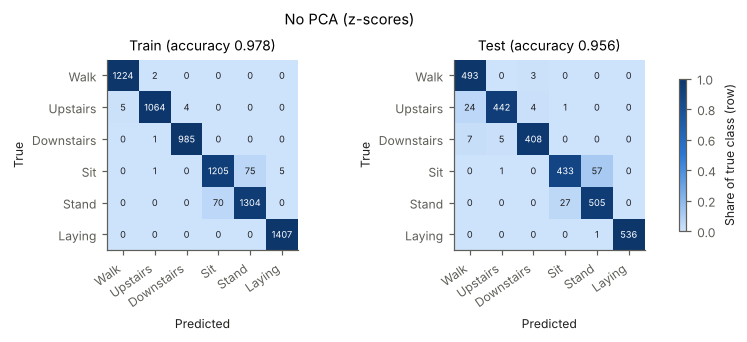

train                              test                        
           precision  recall      F1 support precision  recall      F1 support
Walk          0.9959  0.9984  0.9971    1226    0.9408  0.9940  0.9667     496
Upstairs      0.9963  0.9916  0.9939    1073    0.9866  0.9384  0.9619     471
Downstairs    0.9960  0.9990  0.9975     986    0.9831  0.9714  0.9772     420
Sit           0.9451  0.9370  0.9410    1286    0.9393  0.8819  0.9097     491
Stand         0.9456  0.9491  0.9473    1374    0.8970  0.9492  0.9224     532
Laying        0.9965  1.0000  0.9982    1407    1.0000  0.9981  0.9991     537

accuracy  macro precision  macro recall  macro F1  \
model               split                                                      
PCA (scaled scores) train    0.9805           0.9820        0.9820    0.9820   
                    test     0.9301           0.9311        0.9282    0.9290   
No PCA (z-scores)   train    0.9778           0.9792        0.9792    0.9792   
                    test     0.9559           0.9578        0.9555    0.9562   

                           no classifier >= 0.5  several classifiers >= 0.5  \
model               split                                                     
PCA (scaled scores) train                0.0146                      0.0090   
                    test                 0.0601                      0.0380   
No PCA (z-scores)   train                0.0052                      0.0106   
                    test                 0.0285                      0.0353   

                           features  fit seconds  
model               split                         
PCA (scaled scores) train       103      12.1945  
                    test        103      12.1945  
No PCA (z-scores)   train       540      53.5423  
                    test        540      53.5423

gradient descent accuracy  scikit-learn accuracy  \
model               split                                                     
PCA (scaled scores) train                     0.9805                 0.9819   
                    test                      0.9301                 0.9287   
No PCA (z-scores)   train                     0.9778                 1.0000   
                    test                      0.9559                 0.9454   

                           same prediction  
model               split                   
PCA (scaled scores) train           0.9951  
                    test            0.9698  
No PCA (z-scores)   train           0.9778  
                    test            0.9457

In [32]:
# C27

fit_baseline('No PCA (z-scores)', Z_train, Z_test)
sklearn_reference('No PCA (z-scores)', Z_train, Z_test)
display(convergence_table('No PCA (z-scores)').round(6))
plot_confusion_pair('No PCA (z-scores)', 'no_pca_confusion')
display(class_table('No PCA (z-scores)').round(4))
display(baseline_summary([baseline, 'No PCA (z-scores)']).round(4))
display(pandas.DataFrame(reference_rows).set_index(['model', 'split']).round(4))

The higher test accuracy was achieved by the z-scored no PCA model with an accuracy of 0.9559 and a macro F1 score of 0.9562 in comparison to the the PCA scalled scores with an accuracy of 0.9301 and an F1-score of 0.9290 F1. This does require suing all 540 features though instead of just 103 which increases the time to fit from 2.73 seconds to 8.01. The scikit-learn calculations got a perfect accuracy of 1. on the training set but that dropped down to 0.9440 on the test set. This difference is indicative to a lot of overfitting becuase there wasn't any regularization performed and the features were all highly coorelated.

The gradient descent model performed better than scikit-learn on the test set with an accuracy of 0.9559 but hit the 5000 iteration cap before it converged and becuase it stopped early, it didn't learn all of the training data. In the next stage, we'll test a range of penalties on L!/L2 regularization to see if that makes a differences and gives us a closer gap when working with the full 540 features.

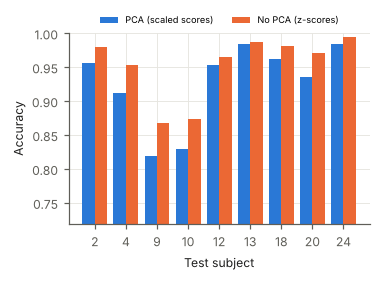

model,No PCA (z-scores),PCA (scaled scores)
subject,,
2,0.9801,0.9570
4,0.9527,0.9117
9,0.8681,0.8194
10,0.8741,0.8299
12,0.9656,0.9531
13,0.9878,0.9847
18,0.9808,0.9615
20,0.9718,0.9350
24,0.9948,0.9843


Lowest baseline subject: 9


,Walk,Upstairs,Downstairs,Sit,Stand,Laying
Walk,52,0,0,0,0,0
Upstairs,16,29,0,3,1,0
Downstairs,0,0,42,0,0,0
Sit,0,2,0,39,8,1
Stand,0,0,0,21,24,0
Laying,0,0,0,0,0,50


In [33]:
# C28

subject_test_ids=subject_test.to_numpy()
subject_rows=[]
for name in (baseline, 'No PCA (z-scores)'):
    correct=fits[name]['pred_test'] == y_test
    for s in numpy.unique(subject_test_ids):
        mask=subject_test_ids == s
        subject_rows.append({'model': name, 'subject': s, 'windows': int(mask.sum()), 'accuracy': correct[mask].mean()})
by_subject=pandas.DataFrame(subject_rows).pivot(index='subject', columns='model', values='accuracy')
models=[baseline, 'No PCA (z-scores)']
fig, ax=plot.subplots(figsize=(col_width, 2.6))
width=.8/len(models)
for j, (name, color) in enumerate(zip(models, (PALETTE['blue'], PALETTE['orange']))):
    ax.bar(numpy.arange(len(by_subject))+(j-(len(models)-1)/2)*width, by_subject[name], width, color=color, label=name)
ax.set_xticks(range(len(by_subject)), by_subject.index)
ax.set_xlabel('Test subject')
ax.set_ylabel('Accuracy')
ax.set_ylim(max(0, by_subject[models].min().min()-.1), 1)
ax.legend(fontsize=6, ncol=2, loc='lower center', bbox_to_anchor=(.5, 1.0))
fig.tight_layout()
save_fig(fig, 'test_accuracy_by_subject')
plot.show()
display(by_subject.round(4))
worst=by_subject[baseline].idxmin()
mask=subject_test_ids == worst
print(f'Lowest baseline subject: {worst}')
display(pandas.DataFrame(confusion(y_test[mask], fits[baseline]['pred_test'][mask], n_classes),
                         index=activity_names, columns=activity_names))

The test accurance has a wide range for the nine unseen participants with a range of 0.9847 to .8194 wheb looking at the pca scaled model. The subject that performed the worst was number 9, and the confusion matrix shows identicial failures compared to the global model but with a greater magnitude. There were 21 stand windows that were misclassified and 16 upstairs windows that were misclassified.

The large variance indicates that the charastics of each individual is highly variable and because of this the cross-validation folds need to be split by subject and not using random windows. If we used a random split that would leak the characteristics of a subjects movement into the training set and giving us an artifically high accuracy.

- The one-vs-all logistic regrassion was a large improvement compared to unsupervised clustering and test accuracy was increased from 0.54 to 0.9301 on 103 PCA components. 
- Even with the imporvement the baseline model was unable to seperate sit from stand well
- Allowing the model to train on 540 features improved accuracy to 0.9559 but the time to fit was almost tripped.
- Generalization is uneven across participants evidenced by accruacies ranging from 81% to 98%
- To help the issue of unchecked weight growth, L1/L2 regularization should be used.
- Dynamic and static classes had almost perfect seperation

In [34]:
# C29

groups=subject_train.to_numpy()
folds=list(GroupKFold(n_splits=n_folds).split(X_train_raw, y_train, groups))
fold_table=pandas.DataFrame([{'fold': f, 'validation subjects': sorted(set(groups[va].tolist())),
                              'train windows': len(tr), 'validation windows': len(va),
                              **dict(zip(activity_names, numpy.bincount(y_train[va], minlength=n_classes)))}
                             for f, (tr, va) in enumerate(folds)]).set_index('fold')
display(fold_table)

,validation subjects,train windows,validation windows,Walk,Upstairs,Downstairs,Sit,Stand,Laying
fold,,,,,,,,,
0,"[15, 22, 25]",6294,1058,174,155,136,186,190,217
1,"[3, 8, 21]",6322,1030,158,147,132,183,204,206
2,"[14, 26, 29]",6293,1059,171,158,143,192,199,196
3,"[1, 6, 30]",6297,1055,217,169,159,164,169,177
4,"[7, 19, 28]",6302,1050,163,142,132,193,205,215
5,"[5, 16, 27]",6308,1044,164,149,138,183,214,196
6,"[11, 17, 23]",6296,1056,179,153,146,185,193,200


In [35]:
# C30

cv_rows=[]

def fold_inputs(f, n_comp):
    tr, va=folds[f]
    fold_prep=make_prep(n_comp, standardize)
    T_tr=fold_prep.fit_transform(X_train_raw.iloc[tr])
    T_va=fold_prep.transform(X_train_raw.iloc[va])
    scale=T_tr.std(axis=0)
    return add_intercept(T_tr/scale), add_intercept(T_va/scale), fold_prep[-1].n_components_

def cv_row(space, penalty, lam, n_comp, f, n_features, pred, y_va, nonzero, n_iter, converged, seconds):
    scores=metrics(y_va, pred, n_classes)
    return {'space': space, 'penalty': penalty, 'lam': lam, 'n_components': n_comp, 'fold': f,
            'features': n_features, 'macro F1': scores['macro F1'], 'accuracy': scores['accuracy'],
            'nonzero weight share': nonzero, 'iterations': n_iter, 'converged': converged, 'fit seconds': seconds}

def pca_fold(f, penalty, n_comp):
    with threadpool_limits(limits=1):
        tr, va=folds[f]
        A_tr, A_va, k_fold=fold_inputs(f, n_comp)
        Y_tr=one_hot(y_train[tr], n_classes)
        theta, rows=None, []
        for lam in sorted(lam_grid, reverse=True):
            start=perf_counter()
            result=fit_penalized(A_tr, Y_tr, lam, penalty, iters=cv_iters, tol=cv_tol, theta0=theta)
            theta=result['theta']
            rows.append(cv_row('PCA', penalty, lam, n_comp, f, k_fold, predict(A_va, theta), y_train[va],
                               float(numpy.mean(theta[1:] != 0)), result['n_iter'], result['converged'], perf_counter()-start))
    return rows

def raw_inputs(X_tr, X_te):
    fold_dedup=DropDuplicateColumns().fit(X_tr)
    fold_scaler=Standardizer(with_std=standardize).fit(fold_dedup.transform(X_tr))
    return fold_scaler.transform(fold_dedup.transform(X_tr)), fold_scaler.transform(fold_dedup.transform(X_te)), fold_dedup.keep_

def sklearn_model(penalty, lam):
    options=(dict(l1_ratio=0, solver='lbfgs') if penalty == 'l2' else
             dict(l1_ratio=1, solver='liblinear', intercept_scaling=intercept_scaling, random_state=0))
    return OneVsRestClassifier(LogisticRegression(C=1/lam, tol=1e-4, max_iter=5000, **options))

def sklearn_fold(f, penalty):
    with threadpool_limits(limits=1):
        tr, va=folds[f]
        R_tr, R_va, _=raw_inputs(X_train_raw.iloc[tr], X_train_raw.iloc[va])
        rows=[]
        for lam in sorted(lam_grid, reverse=True):
            model=sklearn_model(penalty, lam)
            start=perf_counter()
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always', ConvergenceWarning)
                model.fit(R_tr, y_train[tr])
            coef=numpy.vstack([e.coef_ for e in model.estimators_])
            rows.append(cv_row('No PCA', penalty, lam, None, f, R_tr.shape[1], model.predict(R_va), y_train[va],
                               float(numpy.mean(coef != 0)), None,
                               not any(issubclass(w.category, ConvergenceWarning) for w in caught), perf_counter()-start))
    return rows

def run_folds(worker, label, *args):
    start=perf_counter()
    for rows in Parallel(n_jobs=n_jobs, return_as='generator_unordered')(delayed(worker)(f, *args) for f in range(n_folds)):
        cv_rows.extend(rows)
        print(f"  {label}: fold {rows[0]['fold']} done ({perf_counter()-start:.0f} s)", flush=True)

def cv_summary(**where):
    frame=pandas.DataFrame(cv_rows)
    for column, value in where.items():
        frame=frame.loc[frame[column] == value]
    out=frame.groupby(['space', 'penalty', 'n_components', 'lam'], sort=False, dropna=False).agg(
        macro_F1=('macro F1', 'mean'), sd=('macro F1', 'std'), accuracy=('accuracy', 'mean'),
        features=('features', 'mean'), nonzero=('nonzero weight share', 'mean'),
        converged=('converged', 'mean'), seconds=('fit seconds', 'mean'))
    out['se']=out['sd']/numpy.sqrt(n_folds)
    return out.rename(columns={'macro_F1': 'macro F1', 'sd': 'macro F1 sd', 'se': 'macro F1 se',
                               'converged': 'share converged', 'nonzero': 'nonzero weight share',
                               'seconds': 'fit seconds'})

def plot_paths(frames, labels, colors, filename, ylim=None):
    fig, ax=plot.subplots(figsize=(col_width, 2.5))
    for frame, label, color in zip(frames, labels, colors):
        frame=frame.reset_index().sort_values('lam')
        ax.errorbar(frame['lam'], frame['macro F1'], yerr=frame['macro F1 se'], color=color, marker='o', ms=3,
                    lw=1.2, capsize=2, label=label)
    ax.set_xscale('log')
    ax.set_xlabel(r'$\lambda$ (stronger penalty $\rightarrow$)')
    ax.set_ylabel('CV macro F1')
    if ylim:
        ax.set_ylim(*ylim)
    ax.legend(fontsize=6)
    fig.tight_layout()
    save_fig(fig, filename)
    plot.show()

  PCA l2 n_components=0.95: fold 0 done (12 s)


  PCA l2 n_components=0.95: fold 1 done (12 s)


  PCA l2 n_components=0.95: fold 2 done (21 s)


  PCA l2 n_components=0.95: fold 3 done (22 s)


  PCA l2 n_components=0.95: fold 4 done (31 s)


  PCA l2 n_components=0.95: fold 5 done (32 s)


... (5 outputs left out)

  PCA l1 n_components=0.95: fold 4 done (46 s)


  PCA l1 n_components=0.95: fold 5 done (51 s)


  PCA l1 n_components=0.95: fold 6 done (61 s)


macro F1  macro F1 sd  accuracy  features  \
space penalty n_components lam                                                
PCA   l2      0.95         100.0    0.9125       0.0329    0.9124     102.0   
                           30.0     0.9145       0.0349    0.9146     102.0   
                           10.0     0.9189       0.0355    0.9192     102.0   
                           3.0      0.9214       0.0355    0.9220     102.0   
                           1.0      0.9229       0.0338    0.9239     102.0   
                           0.3      0.9214       0.0315    0.9228     102.0   
                           0.1      0.9227       0.0307    0.9241     102.0   
      l1      0.95         100.0    0.8836       0.0435    0.8854     102.0   
                           30.0     0.9083       0.0408    0.9092     102.0   
                           10.0     0.9182       0.0401    0.9191     102.0   
                           3.0      0.9213       0.0366    0.9224     102.0   
                           1.0      0.9233       0.0344    0.9245     102.0   
                           0.3      0.9219       0.0339    0.9236     102.0   
                           0.1      0.9179       0.0337    0.9201     102.0   

                                  nonzero weight share  share converged  \
space penalty n_components lam                                            
PCA   l2      0.95         100.0                1.0000           1.0000   
                           30.0                 1.0000           1.0000   
                           10.0                 1.0000           1.0000   
                           3.0                  1.0000           1.0000   
                           1.0                  1.0000           1.0000   
                           0.3                  1.0000           1.0000   
                           0.1                  1.0000           1.0000   
      l1      0.95         100.0                0.1954           1.0000   
                           30.0                 0.4465           1.0000   
                           10.0                 0.6202           1.0000   
                           3.0                  0.7491           1.0000   
                           1.0                  0.8191           1.0000   
                           0.3                  0.8562           1.0000   
                           0.1                  0.8749           0.8571   

                                  fit seconds  macro F1 se  
space penalty n_components lam                              
PCA   l2      0.95         100.0       0.0700       0.0124  
                           30.0        0.1096       0.0132  
                           10.0        0.1821       0.0134  
                           3.0         0.3301       0.0134  
                           1.0         0.5992       0.0128  
                           0.3         0.9684       0.0119  
                           0.1         1.3477       0.0116  
      l1      0.95         100.0       0.1102       0.0165  
                           30.0        0.2123       0.0154  
                           10.0        0.3840       0.0151  
                           3.0         0.7830       0.0138  
                           1.0         1.2926       0.0130  
                           0.3         2.4393       0.0128  
                           0.1         4.3965       0.0127

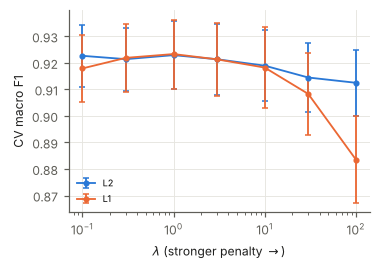

In [36]:
# C31

for penalty in penalties:
    run_folds(pca_fold, f'PCA {penalty} n_components={n_components}', penalty, n_components)
pca_l2=cv_summary(space='PCA', penalty='l2', n_components=n_components)
pca_l1=cv_summary(space='PCA', penalty='l1', n_components=n_components)
display(pandas.concat([pca_l2, pca_l1]).round(4))
plot_paths([pca_l2, pca_l1], ['L2', 'L1'], [PALETTE['blue'], PALETTE['orange']], 'pca_l1_l2_paths')

The results with 95% variance show that every tested $\lambda$ is within about 0.005 of the peak which is less than the standard error. That tells us that the penality doesn't make much difference in the tested range. The test with the highest penalty $\lambda = 100$ show a small decrease in performance for L2 (0.9125) but a much more significant degredation for L1 (0.8836). This is becuase $\lambda = 100$ L1 assignes about 80% of the PCA weights to zero and that removes information that can be used for the model to make predictions. In L2, the weights are moved closer to zero but they are not elininated.

All of the models converged before 3000 iterations except for L1 at the lowest penalty which only converged six of the seven folds. At the best performing penalty ($\lamda=1$) only about 18% of the PCA weights are zeroed and those don't give us much infomration about which features matter.

In [37]:
# C32

cv_frame=pandas.DataFrame(cv_rows)
best_pca={pen: float(frame['macro F1'].idxmax()[-1]) for pen, frame in (('l2', pca_l2), ('l1', pca_l1))}
per_fold=(cv_frame.loc[(cv_frame['space'] == 'PCA') & (cv_frame['n_components'] == n_components)]
          .loc[lambda d: d.apply(lambda r: r['lam'] == best_pca[r['penalty']], axis=1)]
          .pivot(index='fold', columns='penalty', values='macro F1'))
per_fold.insert(0, 'validation subjects', fold_table['validation subjects'])
display(per_fold.round(4))
print('best lambda per penalty:', best_pca)

penalty,validation subjects,l1,l2
fold,,,
0,"[15, 22, 25]",0.9239,0.9233
1,"[3, 8, 21]",0.9408,0.9412
2,"[14, 26, 29]",0.8655,0.8645
3,"[1, 6, 30]",0.9442,0.9455
4,"[7, 19, 28]",0.9092,0.9132
5,"[5, 16, 27]",0.9061,0.9036
6,"[11, 17, 23]",0.9734,0.9692


best lambda per penalty: {'l2': 1.0, 'l1': 1.0}


The second fold proved to be the most difficult and only gave us an F1 score of ~0.865 and the sixth fold was the easiest and produced an F1 score of 0.973. There was a large gap between the best and worst performing folds (greater than 10%) but the gap between the L1 and L2 penalties on the same folds is extremely small. The differences between the variance and the penalties is so far apart we can't say for sure if one penalty performed better than the other with this dataset.

  PCA l2 n_components=0.9: fold 0 done (8 s)


  PCA l2 n_components=0.9: fold 1 done (9 s)


  PCA l2 n_components=0.9: fold 2 done (16 s)


  PCA l2 n_components=0.9: fold 3 done (17 s)


  PCA l2 n_components=0.9: fold 4 done (25 s)


  PCA l2 n_components=0.9: fold 5 done (26 s)


... (5 outputs left out)

  PCA l2 n_components=0.99: fold 4 done (38 s)


  PCA l2 n_components=0.99: fold 5 done (38 s)


  PCA l2 n_components=0.99: fold 6 done (51 s)


macro F1  macro F1 sd  accuracy  features  \
space penalty n_components lam                                                
PCA   l2      0.90         100.0    0.8855       0.0327    0.8854   63.8571   
                           30.0     0.8910       0.0338    0.8914   63.8571   
                           10.0     0.8953       0.0331    0.8956   63.8571   
                           3.0      0.9006       0.0337    0.9010   63.8571   
                           1.0      0.9058       0.0343    0.9062   63.8571   
                           0.3      0.9064       0.0361    0.9068   63.8571   
                           0.1      0.9061       0.0363    0.9063   63.8571   
              0.95         100.0    0.9125       0.0329    0.9124  102.0000   
                           30.0     0.9145       0.0349    0.9146  102.0000   
                           10.0     0.9189       0.0355    0.9192  102.0000   
                           3.0      0.9214       0.0355    0.9220  102.0000   
                           1.0      0.9229       0.0338    0.9239  102.0000   
                           0.3      0.9214       0.0315    0.9228  102.0000   
                           0.1      0.9227       0.0307    0.9241  102.0000   
              0.99         100.0    0.9280       0.0346    0.9272  178.2857   
                           30.0     0.9280       0.0357    0.9272  178.2857   
                           10.0     0.9285       0.0346    0.9279  178.2857   
                           3.0      0.9300       0.0334    0.9297  178.2857   
                           1.0      0.9285       0.0322    0.9286  178.2857   
                           0.3      0.9286       0.0306    0.9289  178.2857   
                           0.1      0.9277       0.0316    0.9279  178.2857   

                                  nonzero weight share  share converged  \
space penalty n_components lam                                            
PCA   l2      0.90         100.0                   1.0              1.0   
                           30.0                    1.0              1.0   
                           10.0                    1.0              1.0   
                           3.0                     1.0              1.0   
                           1.0                     1.0              1.0   
                           0.3                     1.0              1.0   
                           0.1                     1.0              1.0   
              0.95         100.0                   1.0              1.0   
                           30.0                    1.0              1.0   
                           10.0                    1.0              1.0   
                           3.0                     1.0              1.0   
                           1.0                     1.0              1.0   
                           0.3                     1.0              1.0   
                           0.1                     1.0              1.0   
              0.99         100.0                   1.0              1.0   
                           30.0                    1.0              1.0   
                           10.0                    1.0              1.0   
                           3.0                     1.0              1.0   
                           1.0                     1.0              1.0   
                           0.3                     1.0              1.0   
                           0.1                     1.0              1.0   

                                  fit seconds  macro F1 se  
space penalty n_components lam                              
PCA   l2      0.90         100.0       0.0420       0.0124  
                           30.0        0.0679       0.0128  
                           10.0        0.1175       0.0125  
                           3.0         0.2251       0.0127  
                           1.0         0.3947       0.0130  
                           0.3         0.6038       0.0136  
  

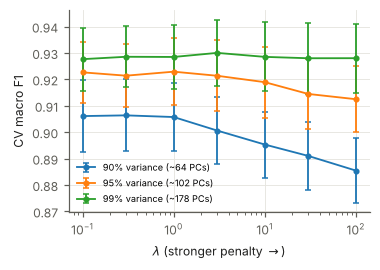

In [38]:
# C33

for n_comp in component_grid:
    if n_comp != n_components:
        run_folds(pca_fold, f'PCA l2 n_components={n_comp}', 'l2', n_comp)
k_frames=[cv_summary(space='PCA', penalty='l2', n_components=n) for n in component_grid]
display(pandas.concat(k_frames).round(4))
plot_paths(k_frames, [f"{n:.0%} variance (~{round(f['features'].iloc[0])} PCs)" for n, f in zip(component_grid, k_frames)],
           plot.get_cmap('tab10').colors[:len(k_frames)], 'pca_components_paths')

When we make the PCA variance threshold larger, performance improved but the returns decrease as the variance grows larger. Moving from 90% to 95% only gives us an improvement of about 0.016 and that is slightly larger than the standard error. If we increase to 99% that gives us an improvement of about 0.007 which is within on standard error so it's not a reliable improvement. 

If we keep the k value at 95% it will make the time to fit much smaller because we only use 102 components instead of 178 which is an acceptable tradeoff.

  No PCA l2: fold 0 done (13 s)


  No PCA l2: fold 1 done (15 s)


  No PCA l2: fold 2 done (28 s)


  No PCA l2: fold 3 done (29 s)


  No PCA l2: fold 5 done (41 s)


  No PCA l2: fold 4 done (41 s)


... (5 outputs left out)

  No PCA l1: fold 5 done (138 s)


  No PCA l1: fold 4 done (141 s)


  No PCA l1: fold 6 done (186 s)


macro F1  macro F1 sd  accuracy  features  \
space  penalty n_components lam                                                
No PCA l2      NaN          100.0    0.9259       0.0375    0.9266     540.0   
                            30.0     0.9320       0.0371    0.9324     540.0   
                            10.0     0.9347       0.0375    0.9349     540.0   
                            3.0      0.9379       0.0358    0.9383     540.0   
                            1.0      0.9375       0.0351    0.9378     540.0   
                            0.3      0.9321       0.0369    0.9331     540.0   
                            0.1      0.9296       0.0361    0.9307     540.0   
       l1      NaN          100.0    0.9120       0.0388    0.9144     540.0   
                            30.0     0.9305       0.0397    0.9322     540.0   
                            10.0     0.9368       0.0364    0.9380     540.0   
                            3.0      0.9408       0.0358    0.9418     540.0   
                            1.0      0.9417       0.0349    0.9425     540.0   
                            0.3      0.9400       0.0346    0.9400     540.0   
                            0.1      0.9372       0.0360    0.9364     540.0   

                                   nonzero weight share  share converged  \
space  penalty n_components lam                                            
No PCA l2      NaN          100.0                1.0000              1.0   
                            30.0                 1.0000              1.0   
                            10.0                 1.0000              1.0   
                            3.0                  1.0000              1.0   
                            1.0                  1.0000              1.0   
                            0.3                  1.0000              1.0   
                            0.1                  1.0000              1.0   
       l1      NaN          100.0                0.0369              1.0   
                            30.0                 0.0721              1.0   
                            10.0                 0.1119              1.0   
                            3.0                  0.1566              1.0   
                            1.0                  0.1972              1.0   
                            0.3                  0.2513              1.0   
                            0.1                  0.3408              1.0   

                                   fit seconds  macro F1 se  
space  penalty n_components lam                              
No PCA l2      NaN          100.0       0.8431       0.0142  
                            30.0        1.0284       0.0140  
                            10.0        1.2991       0.0142  
                            3.0         1.1305       0.0135  
                            1.0         1.1214       0.0133  
                            0.3         1.0973       0.0139  
                            0.1         1.1655       0.0137  
       l1      NaN          100.0       1.8630       0.0147  
                            30.0        2.2982       0.0150  
                            10.0        2.8301       0.0138  
                            3.0         3.7881       0.0135  
                            1.0         5.3887       0.0132  
                            0.3         9.2534       0.0131  
                            0.1        15.1129       0.0136

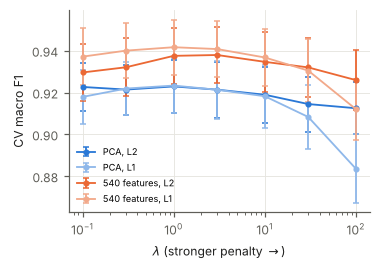

L1, lambda = 1.0: non-zero weights per activity model


,Walk,Upstairs,Downstairs,Sit,Stand,Laying
non-zero of 540,113,149,113,149,143,23


features used by at least one model: 312 of 540


,Walk,Upstairs,Downstairs,Sit,Stand,Laying
1,fBodyAccMag-energy() (-5.01),tBodyAccJerk-min()-X (-2.48),tBodyAccJerk-max()-X (+2.26),tBodyGyroJerk-entropy()-X (-10.60),tBodyGyroJerk-entropy()-X (+10.47),tGravityAcc-max()-X (-2.81)
2,"fBodyAcc-bandsEnergy()-1,8-X (-2.94)","fBodyAccJerk-bandsEnergy()-1,8-X (-2.09)","tBodyAcc-correlation()-X,Y (-2.10)",tGravityAcc-max()-X (+4.48),tGravityAcc-mean()-Y (-5.50),"angle(X,gravityMean) (+1.34)"
3,tBodyAccJerk-entropy()-Z (+2.76),tGravityAcc-max()-Y (-1.70),fBodyAccMag-energy() (+1.52),tGravityAcc-mean()-Y (+3.96),tBodyAccJerk-entropy()-Z (-4.17),tGravityAcc-sma() (-1.25)
4,tBodyAccJerk-entropy()-X (+2.19),"tBodyGyroJerk-arCoeff()-Z,1 (+1.49)","tBodyAcc-correlation()-Y,Z (-1.41)",tGravityAcc-mean()-X (+3.82),tGravityAcc-max()-X (+3.35),tGravityAcc-mean()-X (-1.21)
5,"tBodyAcc-correlation()-X,Y (+1.70)",tBodyAcc-entropy()-X (+1.35),tBodyAcc-entropy()-Z (+1.27),tBodyGyroJerk-entropy()-Y (+3.44),tBodyGyroMag-entropy() (-2.77),tGravityAcc-min()-X (-1.15)


In [39]:
# C34

for penalty in penalties:
    run_folds(sklearn_fold, f'No PCA {penalty}', penalty)
raw_l2=cv_summary(space='No PCA', penalty='l2')
raw_l1=cv_summary(space='No PCA', penalty='l1')
display(pandas.concat([raw_l2, raw_l1]).round(4))
plot_paths([pca_l2, pca_l1, raw_l2, raw_l1], ['PCA, L2', 'PCA, L1', '540 features, L2', '540 features, L1'],
           [PALETTE['blue'], '#8fb8ea', PALETTE['orange'], '#f2a98a'], 'pca_vs_features_paths')

lam_l1=float(raw_l1['macro F1'].idxmax()[-1])
R_full, R_full_test, raw_names=raw_inputs(X_train_raw, X_test_raw)
l1_model=sklearn_model('l1', lam_l1).fit(R_full, y_train)
coef=pandas.DataFrame(numpy.vstack([e.coef_ for e in l1_model.estimators_]).T, index=raw_names, columns=activity_names)
print(f'L1, lambda = {lam_l1}: non-zero weights per activity model')
display((coef != 0).sum().to_frame('non-zero of 540').T)
print(f'features used by at least one model: {(coef != 0).any(axis=1).sum()} of {len(coef)}')
display(pandas.DataFrame({name: [f'{f} ({coef.loc[f, name]:+.2f})' for f in coef[name].abs().sort_values(ascending=False).index[:5]]
                          for name in activity_names}, index=range(1, 6)))

The no PCA set with the full 540 features does better with cross validation. The best performing model, the L1 model with $\lambda=1$, has an F1 score of 0.9417 and the best performing PCA dataset, L2 model with 0.99 variance, has a F1 score of 0.9300. The gap between the two (+0.012) is just shy of the standard error and is the same ranking that we saw on the unregularized test. The full 540 feature set performed better than the PCA set there as well. With a penalty of 1 312 of the 540 features are used by at least one of the models but the laying model only needs 21.

Using L1 on the raw feature set does capture some of the insights that PCA removes. The top features make sense because they are different physical positions with different angles to gravity that can be measured by the sensors and this is the name as what we saw in the first set of test examining the gravity angles.

In [40]:
#testing / validation

A_tr0, A_va0, _=fold_inputs(0, n_components)
tr0, va0=folds[0]
Y_tr0=one_hot(y_train[tr0], n_classes)
check_rows=[]
for penalty in penalties:
    ours=fit_penalized(A_tr0, Y_tr0, 1.0, penalty, iters=20000, tol=1e-7)
    options=(dict(l1_ratio=0, solver='lbfgs') if penalty == 'l2' else
             dict(l1_ratio=1, solver='liblinear', intercept_scaling=100, random_state=0))
    ref=OneVsRestClassifier(LogisticRegression(C=1.0, tol=1e-8, max_iter=2000, **options)).fit(A_tr0[:, 1:], y_train[tr0])
    ref_theta=numpy.vstack([numpy.r_[e.intercept_, e.coef_[0]] for e in ref.estimators_]).T
    check_rows.append({'penalty': penalty, 'converged': ours['converged'], 'steps': ours['n_iter'],
                       'objective (ours)': objective(A_tr0, Y_tr0, ours['theta'], 1.0, penalty).sum(),
                       'objective (scikit-learn)': objective(A_tr0, Y_tr0, ref_theta, 1.0, penalty).sum(),
                       'same validation prediction': numpy.mean(predict(A_va0, ours['theta']) == ref.predict(A_va0[:, 1:]))})
display(pandas.DataFrame(check_rows).set_index('penalty'))

,converged,steps,objective (ours),objective (scikit-learn),same validation prediction
penalty,,,,,
l2,True,452,0.191924,0.191924,1.0
l1,True,1126,0.197717,0.197717,1.0


In [41]:
# C35

everything=cv_summary().reset_index()
best=everything.loc[everything['macro F1'].idxmax()]
cutoff=best['macro F1']-best['macro F1 se']
same_family=((everything['space'] == best['space']) & (everything['penalty'] == best['penalty']) &
             (everything['n_components'].fillna(-1) == (-1 if pandas.isna(best['n_components']) else best['n_components'])))
family_rows=everything.loc[same_family & (everything['macro F1'] >= cutoff)]
one_se=family_rows.loc[family_rows['lam'].idxmax()]
summary_cols=['space', 'penalty', 'n_components', 'lam', 'features', 'macro F1', 'macro F1 se', 'accuracy', 'nonzero weight share']
display(everything.loc[everything.groupby(['space', 'penalty', 'n_components'], dropna=False)['macro F1'].idxmax(),
                       summary_cols].sort_values('macro F1', ascending=False).round(4))
print(f"Best: {best['space']}, {best['penalty']}, lambda={best['lam']:g} (macro F1 {best['macro F1']:.4f} +/- {best['macro F1 se']:.4f})")
print(f"One-SE: {one_se['space']}, {one_se['penalty']}, lambda={one_se['lam']:g} (macro F1 {one_se['macro F1']:.4f})")
print(f"Final: {final_space}, {final_penalty}, lambda={final_lam:g}")

,space,penalty,n_components,lam,features,macro F1,macro F1 se,accuracy,nonzero weight share
39,No PCA,l1,NaN,1.0,540.0000,0.9417,0.0132,0.9425,0.1972
31,No PCA,l2,NaN,3.0,540.0000,0.9379,0.0135,0.9383,1.0000
24,PCA,l2,0.99,3.0,178.2857,0.9300,0.0126,0.9297,1.0000
11,PCA,l1,0.95,1.0,102.0000,0.9233,0.0130,0.9245,0.8191
4,PCA,l2,0.95,1.0,102.0000,0.9229,0.0128,0.9239,1.0000
19,PCA,l2,0.90,0.3,63.8571,0.9064,0.0136,0.9068,1.0000


Best: No PCA, l1, lambda=1 (macro F1 0.9417 +/- 0.0132)
One-SE: No PCA, l1, lambda=30 (macro F1 0.9305)
Final: No PCA, l1, lambda=30


- The cross validation folds were split by subjet so that each validation fold just has participants that haven't been seen. The performance of the models from fold to fold had a lot of variance becuase the way individuals move has a lot of variation. 
- We could see that using the 95% variance gave us a reasonable option; when we tried 90% the accuracy suffered and 99% doubled the number of features and didn't give us a significant improvement. 
- When logistic was performed on all of the 540 features that always outperformed the PCA-reduced dataset using the most optimal $\lambda$. Using L1 regularization on the raw features did fix the overfitting issue that was apparent in the baseline tests so the model was able to use the full dataset.
- The L1 pentaly that was used with the raw features was able to zero features that weren't relivent and assign the highest weight to the features the seperate sitting from standing.
- Going by the createria of a single standard error we would use the L1 model on all 540 features with $\lambda=30$/

In [42]:
# C36

def fit_gaussian_nb(X, y, var_smoothing=1e-9):
    X=numpy.asarray(X, dtype=float)
    y=numpy.asarray(y)
    classes=numpy.unique(y)
    epsilon=var_smoothing*X.var(axis=0).max()
    means=numpy.array([X[y == c].mean(axis=0) for c in classes])
    variances=numpy.array([X[y == c].var(axis=0) for c in classes])+epsilon
    log_prior=numpy.log(numpy.array([numpy.mean(y == c) for c in classes]))
    return dict(classes=classes, log_prior=log_prior, means=means, variances=variances)

def joint_log_likelihood(model, X):
    X=numpy.asarray(X, dtype=float)
    precision=1.0/model['variances']
    log_norm=-0.5*numpy.sum(numpy.log(2*numpy.pi*model['variances']), axis=1)
    squared=(X**2)@precision.T-2*X@(model['means']*precision).T+numpy.sum(model['means']**2*precision, axis=1)
    return model['log_prior']+log_norm-0.5*squared

def nb_predict_log_proba(model, X):
    jll=joint_log_likelihood(model, X)
    top=jll.max(axis=1, keepdims=True)
    return jll-(top+numpy.log(numpy.exp(jll-top).sum(axis=1, keepdims=True)))

def nb_predict_proba(model, X):
    return numpy.exp(nb_predict_log_proba(model, X))

def evidence_by_input(model, x, class_a, class_b):
    a=int(numpy.flatnonzero(model['classes'] == class_a)[0])
    b=int(numpy.flatnonzero(model['classes'] == class_b)[0])
    x=numpy.asarray(x, dtype=float)
    def log_normal(j):
        return -0.5*(numpy.log(2*numpy.pi*model['variances'][j])+(x-model['means'][j])**2/model['variances'][j])
    return log_normal(a)-log_normal(b)

In [43]:
#testing / validation

nb_check=fit_gaussian_nb(T_train[:, :30], y_train, 1e-2)
sk_nb=SkGaussianNB(var_smoothing=1e-2).fit(T_train[:, :30], y_train)
print(numpy.allclose(nb_check['means'], sk_nb.theta_), numpy.allclose(nb_check['variances'], sk_nb.var_))
print(numpy.allclose(nb_predict_log_proba(nb_check, T_test[:, :30]), sk_nb.predict_log_proba(T_test[:, :30]), atol=1e-8))

True True
True


,pooled mean |r| (all windows),within Walk,within Upstairs,within Downstairs,within Sit,within Stand,within Laying,within-class share |r| > 0.5
inputs,,,,,,,,
All 540 z-scored features,0.409,0.230,0.238,0.252,0.325,0.317,0.340,0.202
First 40 PCA components,0.000,0.105,0.112,0.107,0.123,0.136,0.142,0.015


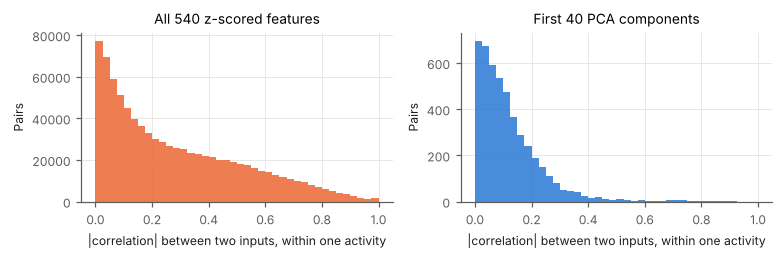

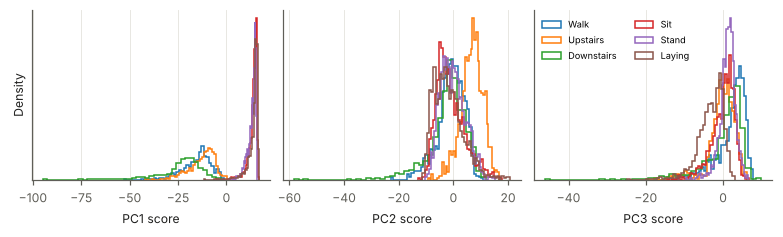

In [44]:
# C37

prep_full=make_prep(None, standardize).fit(X_train_raw)
T_full=prep_full.transform(X_train_raw)

def within_class_abs_r(M):
    values=[]
    for c in range(n_classes):
        Cc=numpy.corrcoef(M[y_train == c], rowvar=False)
        values.append(numpy.abs(Cc[numpy.triu_indices_from(Cc, 1)]))
    return values

inputs={'All 540 z-scored features': Z_train, f'First {nb_check_components} PCA components': T_full[:, :nb_check_components]}
rows, pooled=[], {}
for name, M in inputs.items():
    per_activity=within_class_abs_r(M)
    pooled[name]=numpy.concatenate(per_activity)
    C_all=numpy.corrcoef(M, rowvar=False)
    rows.append({'inputs': name, 'pooled mean |r| (all windows)': numpy.abs(C_all[numpy.triu_indices_from(C_all, 1)]).mean(),
                 **{f'within {activity_names[c]}': v.mean() for c, v in enumerate(per_activity)},
                 'within-class share |r| > 0.5': (pooled[name] > 0.5).mean()})
display(pandas.DataFrame(rows).set_index('inputs').round(3))

fig, axes=plot.subplots(1, 2, figsize=(page_width, 2.4))
for ax, (name, values), color in zip(axes, pooled.items(), (PALETTE['orange'], PALETTE['blue'])):
    ax.hist(values, bins=numpy.linspace(0, 1, 41), color=color, alpha=.85)
    ax.set_xlabel('|correlation| between two inputs, within one activity')
    ax.set_ylabel('Pairs')
    ax.set_title(name)
fig.tight_layout()
save_fig(fig, 'within_class_correlation')
plot.show()

colors=plot.get_cmap('tab10').colors
fig, axes=plot.subplots(1, 3, figsize=(page_width, 2.2))
for j, ax in enumerate(axes):
    for c, name in enumerate(activity_names):
        ax.hist(T_full[y_train == c, j], bins=40, histtype='step', color=colors[c], lw=1, density=True, label=name)
    ax.set_xlabel(f'PC{j+1} score')
    ax.set_yticks([])
axes[0].set_ylabel('Density')
axes[-1].legend(fontsize=6, ncol=2)
fig.tight_layout()
save_fig(fig, 'pc_shapes_by_class')
plot.show()

The 540 raw featreus have a high coorelation with each of the performed activities. Naive Bayes assumes that the features or independent of each other, but this dataset voilates that assumption becuase all but six of the features are derived from data collected by two sensors. Because of this, the model will likely inflate evidence in the dataset and product overconfident predicitons that are skewed.

  fold 0 done (13 s)


  fold 1 done (14 s)


  fold 3 done (26 s)


  fold 2 done (27 s)


  fold 5 done (39 s)


  fold 4 done (40 s)


  fold 6 done (52 s)


var_smoothing,1.000000e-09,1.000000e-06,1.000000e-03,1.000000e-02,1.000000e-01
inputs,,,,,
PCA 5,0.7244,0.7244,0.7227,0.7111,0.6488
PCA 10,0.7552,0.7553,0.7546,0.7459,0.6810
PCA 20,0.7904,0.7904,0.7894,0.7784,0.7017
PCA 30,0.8011,0.8011,0.8040,0.7931,0.7161
PCA 40,0.8007,0.8007,0.8026,0.7925,0.7092
PCA 60,0.7924,0.7925,0.7950,0.7689,0.6879
PCA 80,0.7846,0.7846,0.7845,0.7448,0.6739
PCA 103,0.7818,0.7816,0.7733,0.7234,0.6558
PCA 150,0.7582,0.7580,0.7437,0.6901,0.6355


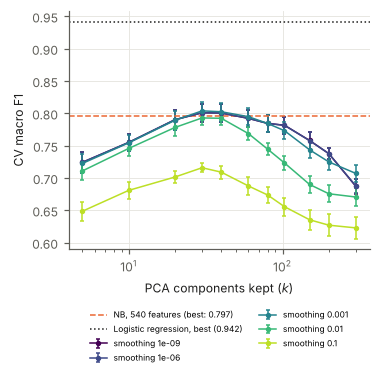

Best: PCA 30, var_smoothing=0.001 (macro F1 0.8040 +/- 0.0134)
One-SE: PCA 30, var_smoothing=0.01 (macro F1 0.7931)


In [45]:
# C38

def nb_fold(f):
    with threadpool_limits(limits=1):
        tr, va=folds[f]
        fold_prep=make_prep(None, standardize).fit(X_train_raw.iloc[tr])
        T_tr, T_va=fold_prep.transform(X_train_raw.iloc[tr]), fold_prep.transform(X_train_raw.iloc[va])
        R_tr, R_va, _=raw_inputs(X_train_raw.iloc[tr], X_train_raw.iloc[va])
        spaces=[(f'PCA {c}', c, T_tr[:, :c], T_va[:, :c]) for c in nb_component_grid if c <= T_tr.shape[1]]
        spaces.append(('No PCA', R_tr.shape[1], R_tr, R_va))
        rows, oof=[], {}
        for label, n_in, A, B in spaces:
            for smoothing in var_smoothing_grid:
                model=fit_gaussian_nb(A, y_train[tr], smoothing)
                P=nb_predict_proba(model, B)
                pred=model['classes'][P.argmax(axis=1)]
                scores=metrics(y_train[va], pred, n_classes)
                rows.append({'inputs': label, 'space': 'No PCA' if label == 'No PCA' else 'PCA', 'n_inputs': n_in,
                             'var_smoothing': smoothing, 'fold': f, 'macro F1': scores['macro F1'], 'accuracy': scores['accuracy']})
                oof[(label, smoothing)]=(va, pred, P.max(axis=1))
    return rows, oof

start=perf_counter()
nb_rows, oof=[], {}
for rows, fold_oof in Parallel(n_jobs=n_jobs, return_as='generator_unordered')(delayed(nb_fold)(f) for f in range(n_folds)):
    nb_rows.extend(rows)
    for key, value in fold_oof.items():
        oof.setdefault(key, []).append(value)
    print(f"  fold {rows[0]['fold']} done ({perf_counter()-start:.0f} s)", flush=True)

nb_cv=pandas.DataFrame(nb_rows)
nb_summary=(nb_cv.groupby(['inputs', 'space', 'n_inputs', 'var_smoothing'], sort=False)
            .agg(macro_F1=('macro F1', 'mean'), sd=('macro F1', 'std'), accuracy=('accuracy', 'mean'))
            .rename(columns={'macro_F1': 'macro F1', 'sd': 'macro F1 sd'}).reset_index())
nb_summary['macro F1 se']=nb_summary['macro F1 sd']/numpy.sqrt(n_folds)
display(nb_summary.pivot(index='inputs', columns='var_smoothing', values='macro F1')
        .reindex([f'PCA {c}' for c in nb_component_grid]+['No PCA']).round(4))

lr_best=everything.loc[everything['macro F1'].idxmax()]
fig, ax=plot.subplots(figsize=(col_width, 3.6))
pca_rows=nb_summary.loc[nb_summary['space'] == 'PCA']
for smoothing, color in zip(var_smoothing_grid, plot.get_cmap('viridis')(numpy.linspace(0, .9, len(var_smoothing_grid)))):
    part=pca_rows.loc[pca_rows['var_smoothing'] == smoothing].sort_values('n_inputs')
    ax.errorbar(part['n_inputs'], part['macro F1'], yerr=part['macro F1 se'], color=color, marker='o', ms=2.5, lw=1,
                capsize=1.5, label=f'smoothing {smoothing:g}')
raw_best=nb_summary.loc[nb_summary['space'] == 'No PCA'].sort_values('macro F1').iloc[-1]
ax.axhline(raw_best['macro F1'], color=PALETTE['orange'], ls='--', lw=1, label=f"NB, 540 features (best: {raw_best['macro F1']:.3f})")
ax.axhline(lr_best['macro F1'], color=PALETTE['ink'], ls=':', lw=1, label=f"Logistic regression, best ({lr_best['macro F1']:.3f})")
ax.set_xscale('log')
ax.set_xlabel('PCA components kept ($k$)')
ax.set_ylabel('CV macro F1')
ax.legend(fontsize=5.5, ncol=2, loc='upper center', bbox_to_anchor=(.5, -0.22))
fig.tight_layout()
save_fig(fig, 'nb_cv_components')
plot.show()

best_nb=nb_summary.loc[nb_summary['macro F1'].idxmax()]
nb_cutoff=best_nb['macro F1']-best_nb['macro F1 se']
nb_one_se=nb_summary.loc[nb_summary['macro F1'] >= nb_cutoff].sort_values(['n_inputs', 'var_smoothing'], ascending=[True, False]).iloc[0]
print(f"Best: {best_nb['inputs']}, var_smoothing={best_nb['var_smoothing']:g} (macro F1 {best_nb['macro F1']:.4f} +/- {best_nb['macro F1 se']:.4f})")
print(f"One-SE: {nb_one_se['inputs']}, var_smoothing={nb_one_se['var_smoothing']:g} (macro F1 {nb_one_se['macro F1']:.4f})")

There is a peak with only 30 PCA components using 0.001 smoothing which gives us a macro F1 score of 0.8040. Logestic Regression with more features causes the F1 score to drop to -0.68 and Logistic Regression reduces the weights on features that are not useful; this is an issue becuase Naive Bayes assumes that all of the features are independent and add data.

The model that uses the full 540 feature set has a lower peask the the PCA model with only 30 features. The Naive Bayes model that performed that best (-.804) was still surpasses by the best Logistic Regression model (-0.948) which demonstrates that the features not being independent are an issue for Naive Bayes.

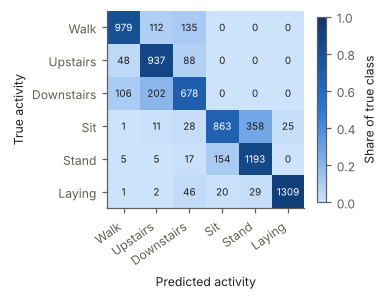

,precision,recall,F1,support
Walk,0.8588,0.7985,0.8276,1226
Upstairs,0.7384,0.8733,0.8002,1073
Downstairs,0.6835,0.6876,0.6855,986
Sit,0.8322,0.6711,0.7430,1286
Stand,0.7551,0.8683,0.8077,1374
Laying,0.9813,0.9303,0.9551,1407


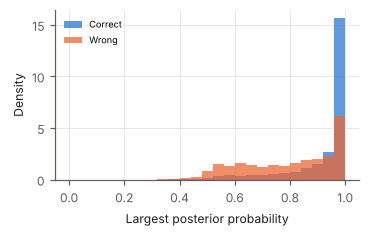

wrong windows with posterior > 0.99: 14.3% of all errors


In [46]:
# C39

def pooled_oof(label, smoothing):
    pred=numpy.empty(len(y_train), dtype=int)
    confidence=numpy.empty(len(y_train))
    for va, p, c in oof[(label, smoothing)]:
        pred[va], confidence[va]=p, c
    return pred, confidence

oof_pred, oof_conf=pooled_oof(best_nb['inputs'], best_nb['var_smoothing'])
table=confusion(y_train, oof_pred, n_classes)
share=table/table.sum(axis=1, keepdims=True)
fig, ax=plot.subplots(figsize=(col_width, col_width*.86))
im=ax.imshow(share, cmap=SEQUENTIAL, vmin=0, vmax=1)
for (i, j), count in numpy.ndenumerate(table):
    ax.text(j, i, str(count), ha='center', va='center', fontsize=6.5, color='white' if share[i, j] > .55 else PALETTE['ink'])
ax.set_xticks(range(n_classes), activity_names, rotation=35, ha='right')
ax.set_yticks(range(n_classes), activity_names)
ax.grid(False)
ax.set_xlabel('Predicted activity')
ax.set_ylabel('True activity')
fig.colorbar(im, ax=ax, label='Share of true class', shrink=.8)
fig.tight_layout()
save_fig(fig, 'nb_oof_confusion')
plot.show()
display(per_class(table, activity_names).round(4))

correct=oof_pred == y_train
fig, ax=plot.subplots(figsize=(col_width, 2.2))
bins=numpy.linspace(0, 1, 26)
ax.hist(oof_conf[correct], bins=bins, density=True, color=PALETTE['blue'], alpha=.75, label='Correct')
ax.hist(oof_conf[~correct], bins=bins, density=True, color=PALETTE['orange'], alpha=.75, label='Wrong')
ax.set_xlabel('Largest posterior probability')
ax.set_ylabel('Density')
ax.legend(fontsize=6)
fig.tight_layout()
save_fig(fig, 'nb_confidence')
plot.show()
print(f'wrong windows with posterior > 0.99: {(oof_conf[~correct] > 0.99).mean():.1%} of all errors')

The feature pairs that both Naive Bays and Logistic Regression had issues with were the same but Naive Bayes had a much more difficult time. The postures sit versus stand are often confuses and the movements all seem to blend together. Naive Bayes also very confident in it's predictions even though they are incorrect.

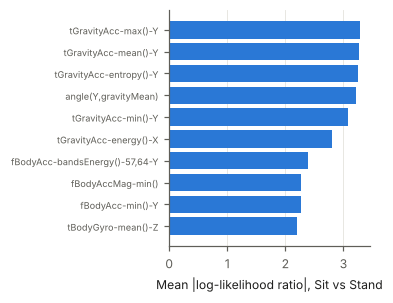

,mean |evidence|,mean evidence on true Sit windows
tGravityAcc-max()-Y,3.285,4.532
tGravityAcc-mean()-Y,3.259,4.493
tGravityAcc-entropy()-Y,3.251,3.926
"angle(Y,gravityMean)",3.219,4.490
tGravityAcc-min()-Y,3.077,4.196
tGravityAcc-energy()-X,2.794,3.341
"fBodyAcc-bandsEnergy()-57,64-Y",2.395,1.905
fBodyAccMag-min(),2.264,1.737
fBodyAcc-min()-Y,2.262,1.789
tBodyGyro-mean()-Z,2.193,1.906


Top 10 features hold 16.5% of the total evidence


In [47]:
# C40

raw_smoothing=raw_best['var_smoothing']
sit, stand=activity_names.index('Sit'), activity_names.index('Stand')
raw_model=fit_gaussian_nb(R_full, y_train, raw_smoothing)
pair=numpy.flatnonzero(numpy.isin(y_train, [sit, stand]))
evidence=numpy.array([evidence_by_input(raw_model, R_full[i], sit, stand) for i in pair])
reliance=pandas.Series(numpy.abs(evidence).mean(axis=0), index=raw_names).sort_values(ascending=False)
direction=pandas.Series(evidence[y_train[pair] == sit].mean(axis=0), index=raw_names)
top=reliance.index[:top_evidence][::-1]
fig, ax=plot.subplots(figsize=(col_width, 2.8))
ax.barh(range(len(top)), reliance[top], color=PALETTE['blue'])
ax.set_yticks(range(len(top)), top, fontsize=6)
ax.set_xlabel('Mean |log-likelihood ratio|, Sit vs Stand')
ax.grid(axis='y', visible=False)
fig.tight_layout()
save_fig(fig, 'nb_sit_stand_evidence')
plot.show()
display(pandas.DataFrame({'mean |evidence|': reliance[:top_evidence],
                          'mean evidence on true Sit windows': direction[reliance.index[:top_evidence]]}).round(3))
print(f'Top {top_evidence} features hold {reliance[:top_evidence].sum()/reliance.sum():.1%} of the total evidence')

Naive Bayes is using the features tied to gravity in order to seperate sitting from standing. Even though there are clearly features that rank near the top, the top 10 only account for about 17% to the total likelyhood difference. That leaves us doubting that Naive Bayes is explainable becuase the outputs are a blend of hundreds of small signals.

In [48]:
# C41

cv_frame=pandas.DataFrame(cv_rows)
lr_mask=(cv_frame['space'] == final_space) & (cv_frame['penalty'] == final_penalty) & (cv_frame['lam'] == final_lam)
if final_space == 'PCA':
    lr_mask &= cv_frame['n_components'] == (final_n_components or n_components)
lr_folds=cv_frame.loc[lr_mask].set_index('fold')['macro F1'].sort_index()
nb_folds=nb_cv.loc[(nb_cv['inputs'] == best_nb['inputs']) & (nb_cv['var_smoothing'] == best_nb['var_smoothing'])].set_index('fold')['macro F1'].sort_index()
paired=pandas.DataFrame({'validation subjects': fold_table['validation subjects'],
                         'logistic regression': lr_folds, f"Naive Bayes ({best_nb['inputs']})": nb_folds})
paired['difference (NB - LR)']=paired.iloc[:, 2]-paired.iloc[:, 1]
display(paired.round(4))
d=paired['difference (NB - LR)']
print(f'mean difference {d.mean():+.4f} (SE {d.std()/numpy.sqrt(n_folds):.4f}); Naive Bayes lower in {int((d < 0).sum())} of {n_folds} folds')

,validation subjects,logistic regression,Naive Bayes (PCA 30),difference (NB - LR)
fold,,,,
0,"[15, 22, 25]",0.9231,0.7898,-0.1333
1,"[3, 8, 21]",0.9593,0.8031,-0.1562
2,"[14, 26, 29]",0.8744,0.7582,-0.1162
3,"[1, 6, 30]",0.9581,0.8059,-0.1522
4,"[7, 19, 28]",0.9209,0.7951,-0.1258
5,"[5, 16, 27]",0.8917,0.8760,-0.0156
6,"[11, 17, 23]",0.9857,0.8000,-0.1858


mean difference -0.1264 (SE 0.0204); Naive Bayes lower in 7 of 7 folds


Logistic regression models outperforms Naive Bayes on all seven cross validation folds with a wide difference in mean. Both models struggled with the mode difficult folds (5 and 6) which means that some individuals may have movement characteristics that are more difficult to classify. 

The huge differnce in performance between Naive Bayes and Logistic Regression is becuase the data is all highly cooreldated and Naive Bayes struggles with features that are not independent.

- Naive Bayes was used so that we could show what happens with highly coorelated features. The 540 features in this dataset do not conform to the assumption that Naive Bayes requires and that is the features are all independent and provide useful data.
- The cross validation tests for Naive Bayes gave us a macro F1 score of 0.8040 with the fist 30 PCA components. When more components were added, performance got worse. 
- The model was overconfident in its predictions becuase the features were not independent. Naive Bayes had issues with the same feature pairs as logistic regression did. 
- The Naive Bayes predictions weren't explainable; the top ten features only accounted for about 17% of the total decision weight, so the remaining was from the over 500 remaining features.
- Logistic Regression demonstrated better performance in every cross validation fold with an average macro F1 score of -0.137.

In [49]:
# C42

def fit_logistic(space, penalty, lam, n_comp):
    start=perf_counter()
    if space == 'PCA':
        final_prep=make_prep(n_comp, standardize)
        T_tr=final_prep.fit_transform(X_train_raw)
        T_te=final_prep.transform(X_test_raw)
        scale=T_tr.std(axis=0)
        A_tr, A_te=add_intercept(T_tr/scale), add_intercept(T_te/scale)
        result=fit_penalized(A_tr, Y_train, lam, penalty, iters=cv_iters, tol=cv_tol)
        weights=result['theta'][1:]
        P_tr, P_te=predict_proba(A_tr, result['theta']), predict_proba(A_te, result['theta'])
        details=dict(inputs=f'{T_tr.shape[1]} PCA components', converged=result['converged'], coefficients=None)
    else:
        model=sklearn_model(penalty, lam)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            model.fit(R_full, y_train)
        weights=numpy.vstack([e.coef_[0] for e in model.estimators_]).T
        P_tr=numpy.column_stack([e.predict_proba(R_full)[:, 1] for e in model.estimators_])
        P_te=numpy.column_stack([e.predict_proba(R_full_test)[:, 1] for e in model.estimators_])
        details=dict(inputs=f'{R_full.shape[1]} z-scored features',
                     converged=not any(issubclass(w.category, ConvergenceWarning) for w in caught),
                     coefficients=pandas.DataFrame(weights, index=raw_names, columns=activity_names))
    details.update(nonzero_share=float(numpy.mean(weights != 0)), fit_seconds=perf_counter()-start)
    return P_tr, P_te, details

def fit_nb_final(inputs, var_smoothing):
    if inputs == 'No PCA':
        A_tr, A_te=R_full, R_full_test
    else:
        A_tr, A_te=T_full[:, :inputs], prep_full.transform(X_test_raw)[:, :inputs]
    model=fit_gaussian_nb(A_tr, y_train, var_smoothing)
    return nb_predict_proba(model, A_tr), nb_predict_proba(model, A_te)

final_label=f"{'PCA' if final_space == 'PCA' else 'All features'}, {final_penalty.upper()}, λ={final_lam:g} (final)"
P_train_final, P_test_final, final_details=fit_logistic(final_space, final_penalty, final_lam, final_n_components)
pred_train_final, pred_test_final=P_train_final.argmax(axis=1), P_test_final.argmax(axis=1)
nb_label=f"Naive Bayes, {'540 features' if nb_final_inputs == 'No PCA' else str(nb_final_inputs)+' PCs'}, smoothing {nb_final_var_smoothing:g}"
P_train_nb, P_test_nb=fit_nb_final(nb_final_inputs, nb_final_var_smoothing)
pred_train_nb, pred_test_nb=P_train_nb.argmax(axis=1), P_test_nb.argmax(axis=1)
print(final_label, {key: value for key, value in final_details.items() if key != 'coefficients'})
print(nb_label)

All features, L1, λ=30 (final) {'inputs': '540 z-scored features', 'converged': True, 'nonzero_share': 0.07808641975308642, 'fit_seconds': 2.588953429999947}
Naive Bayes, 30 PCs, smoothing 0.01


accuracy  macro precision  \
All features, L1, λ=30 (final)      train    0.9735           0.9746   
                                    test     0.9359           0.9393   
Naive Bayes, 30 PCs, smoothing 0.01 train    0.8225           0.8312   
                                    test     0.7995           0.8239   

                                           macro recall  macro F1  
All features, L1, λ=30 (final)      train        0.9745    0.9745  
                                    test         0.9347    0.9360  
Naive Bayes, 30 PCs, smoothing 0.01 train        0.8146    0.8128  
                                    test         0.7882    0.7801

logistic regression                         Naive Bayes          \
                     precision  recall      F1 support   precision  recall   
Walk                    0.9218  0.9980  0.9584     496      0.7414  0.9597   
Upstairs                0.9391  0.9172  0.9280     471      0.8245  0.9575   
Downstairs              0.9873  0.9238  0.9545     420      0.8884  0.4548   
Sit                     0.9272  0.8554  0.8898     491      0.8255  0.5010   
Stand                   0.8603  0.9380  0.8975     532      0.6697  0.9530   
Laying                  1.0000  0.9758  0.9877     537      0.9939  0.9032   

                            
                F1 support  
Walk        0.8366     496  
Upstairs    0.8861     471  
Downstairs  0.6016     420  
Sit         0.6236     491  
Stand       0.7867     532  
Laying      0.9463     537

one-vs-all disagreements on test: {'no classifier >= 0.5': 0.075, 'several classifiers >= 0.5': 0.0295}


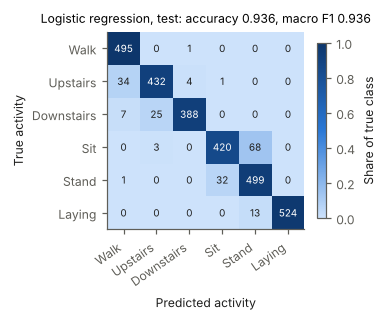

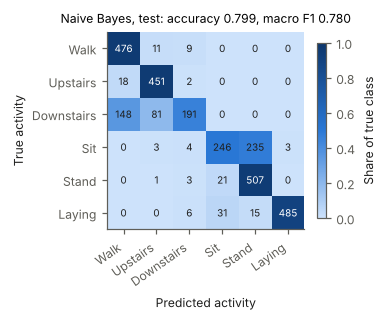

In [50]:
# C43

final_table=confusion(y_test, pred_test_final, n_classes)
nb_table=confusion(y_test, pred_test_nb, n_classes)
final_scores={split: metrics(truth, pred, n_classes) for split, truth, pred in
              (('train', y_train, pred_train_final), ('test', y_test, pred_test_final))}
nb_scores={split: metrics(truth, pred, n_classes) for split, truth, pred in
           (('train', y_train, pred_train_nb), ('test', y_test, pred_test_nb))}
display(pandas.concat({final_label: pandas.DataFrame(final_scores).T, nb_label: pandas.DataFrame(nb_scores).T}).round(4))
display(pandas.concat({'logistic regression': per_class(final_table, activity_names),
                       'Naive Bayes': per_class(nb_table, activity_names)}, axis=1).round(4))
print('one-vs-all disagreements on test:', {key: round(value, 4) for key, value in ova_agreement(P_test_final).items()})

def plot_confusion(table, title, filename):
    share=table/table.sum(axis=1, keepdims=True)
    fig, ax=plot.subplots(figsize=(col_width, col_width*0.86))
    im=ax.imshow(share, cmap=SEQUENTIAL, vmin=0, vmax=1)
    for (i, j), count in numpy.ndenumerate(table):
        ax.text(j, i, str(count), ha='center', va='center', fontsize=6.5, color='white' if share[i, j] > .55 else PALETTE['ink'])
    ax.set_xticks(range(n_classes), activity_names, rotation=35, ha='right')
    ax.set_yticks(range(n_classes), activity_names)
    ax.set_xlabel('Predicted activity')
    ax.set_ylabel('True activity')
    ax.grid(False)
    ax.set_title(title, fontsize=8)
    fig.colorbar(im, ax=ax, label='Share of true class', shrink=.8)
    fig.tight_layout()
    save_fig(fig, filename)
    plot.show()

plot_confusion(final_table, f"Logistic regression, test: accuracy {final_scores['test']['accuracy']:.3f}, "
                            f"macro F1 {final_scores['test']['macro F1']:.3f}", 'final_confusion')
plot_confusion(nb_table, f"Naive Bayes, test: accuracy {nb_scores['test']['accuracy']:.3f}, "
                         f"macro F1 {nb_scores['test']['macro F1']:.3f}", 'nb_final_confusion')

In [51]:
# C44

rng=numpy.random.default_rng(bootstrap_seed)
test_ids=numpy.unique(subject_test_ids)
subject_index={s: numpy.flatnonzero(subject_test_ids == s) for s in test_ids}
draws=[numpy.concatenate([subject_index[s] for s in rng.choice(test_ids, len(test_ids), replace=True)])
       for _ in range(bootstrap_draws)]

def bootstrap(pred):
    return numpy.array([[metrics(y_test[idx], pred[idx], n_classes)[name] for name in ('accuracy', 'macro F1')]
                        for idx in draws])

final_boot=bootstrap(pred_test_final)
low, high=numpy.percentile(final_boot, [2.5, 97.5], axis=0)
for j, name in enumerate(('accuracy', 'macro F1')):
    print(f"{name}: {final_scores['test'][name]:.4f} (95% subject-bootstrap interval {low[j]:.4f} to {high[j]:.4f})")
final_by_subject=pandas.DataFrame({'windows': [len(subject_index[s]) for s in test_ids],
                                   'accuracy': [numpy.mean(pred_test_final[subject_index[s]] == y_test[subject_index[s]])
                                                for s in test_ids]}, index=pandas.Index(test_ids, name='subject'))
display(final_by_subject.T.round(4))

accuracy: 0.9359 (95% subject-bootstrap interval 0.8929 to 0.9699)
macro F1: 0.9360 (95% subject-bootstrap interval 0.8939 to 0.9696)


subject,2,4,9,10,12,13,18,20,24
windows,302.0000,317.0000,288.0000,294.0000,320.0000,327.0000,364.0000,354.0000,381.0
accuracy,0.9735,0.9401,0.8403,0.8061,0.9625,0.9878,0.9478,0.9322,1.0


,CV macro F1,accuracy,macro F1,macro F1 95% low,macro F1 95% high,difference vs final,difference 95% low,difference 95% high
model,,,,,,,,
"All features, L1, λ=30 (final)",0.9305,0.9359,0.9360,0.8939,0.9696,0.0000,NaN,NaN
"Naive Bayes, 30 PCs, smoothing 0.01",0.7931,0.7995,0.7801,0.7471,0.8071,-0.1559,-0.2119,-0.1014
"K-means, k=6",NaN,0.5405,0.4880,0.4360,0.5339,-0.4480,-0.5077,-0.3965
"PCA, no penalty",NaN,0.9301,0.9290,0.8887,0.9599,-0.0070,-0.0168,0.0028
"All features, no penalty",NaN,0.9559,0.9562,0.9240,0.9799,0.0202,0.0069,0.0347
"All features, L1, λ=1 (CV-best)",0.9417,0.9610,0.9612,0.9313,0.9824,0.0252,0.0081,0.0444


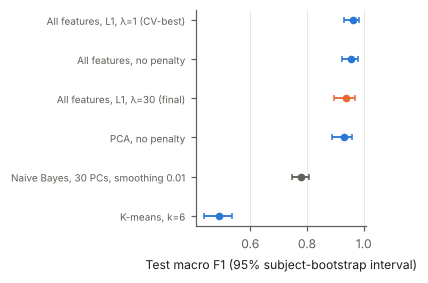

In [52]:
# C45

kmeans_run=runs[f'PCA / k={activity_clusters} / K-means']
comparison={final_label: pred_test_final, nb_label: pred_test_nb,
            'K-means, k=6': numpy.array([kmeans_run['mapping'].get(c, -1) for c in kmeans_run['test']]),
            'PCA, no penalty': fits[baseline]['pred_test'],
            'All features, no penalty': fits['No PCA (z-scores)']['pred_test']}
cv_scores={final_label: float(everything.loc[(everything['space'] == final_space) & (everything['penalty'] == final_penalty)
                                             & (everything['lam'] == final_lam), 'macro F1'].iloc[0]),
           nb_label: float(nb_summary.loc[(nb_summary['inputs'] == (f'PCA {nb_final_inputs}' if nb_final_inputs != 'No PCA' else 'No PCA'))
                                          & numpy.isclose(nb_summary['var_smoothing'], nb_final_var_smoothing), 'macro F1'].iloc[0])}
best_setting=(best['space'], best['penalty'], float(best['lam']))
if best_setting != (final_space, final_penalty, final_lam):
    best_label=f"{'PCA' if best['space'] == 'PCA' else 'All features'}, {best['penalty'].upper()}, λ={best['lam']:g} (CV-best)"
    _, P_best, _=fit_logistic(best['space'], best['penalty'], float(best['lam']),
                              None if pandas.isna(best['n_components']) else float(best['n_components']))
    comparison[best_label]=P_best.argmax(axis=1)
    cv_scores[best_label]=float(best['macro F1'])

rows=[]
for name, pred in comparison.items():
    boot=bootstrap(pred)
    scores=metrics(y_test, pred, n_classes)
    lo, hi=numpy.percentile(boot, [2.5, 97.5], axis=0)
    d_lo, d_hi=numpy.percentile(boot[:, 1]-final_boot[:, 1], [2.5, 97.5])
    rows.append({'model': name, 'CV macro F1': cv_scores.get(name, numpy.nan), 'accuracy': scores['accuracy'],
                 'macro F1': scores['macro F1'], 'macro F1 95% low': lo[1], 'macro F1 95% high': hi[1],
                 'difference vs final': scores['macro F1']-final_scores['test']['macro F1'],
                 'difference 95% low': d_lo if name != final_label else numpy.nan,
                 'difference 95% high': d_hi if name != final_label else numpy.nan})
model_table=pandas.DataFrame(rows).set_index('model')
display(model_table.round(4))

order=model_table.sort_values('macro F1').index
fig, ax=plot.subplots(figsize=(col_width, 0.32*len(order)+0.7))
for i, name in enumerate(order):
    row=model_table.loc[name]
    color=PALETTE['orange'] if name == final_label else (PALETTE['ink2'] if name == nb_label else PALETTE['blue'])
    ax.errorbar(row['macro F1'], i, xerr=[[row['macro F1']-row['macro F1 95% low']], [row['macro F1 95% high']-row['macro F1']]],
                fmt='o', color=color, ms=4, capsize=2, lw=1.2)
ax.set_yticks(range(len(order)), order, fontsize=6.5)
ax.set_xlabel('Test macro F1 (95% subject-bootstrap interval)')
ax.grid(axis='y', visible=False)
fig.tight_layout()
save_fig(fig, 'model_comparison')
plot.show()

,true,predicted,windows,share of all errors
0,Sit,Stand,68,0.360
1,Upstairs,Walk,34,0.180
2,Stand,Sit,32,0.169
3,Downstairs,Upstairs,25,0.132
4,Laying,Stand,13,0.069
5,Downstairs,Walk,7,0.037
6,Upstairs,Downstairs,4,0.021
7,Sit,Upstairs,3,0.016


189 test errors; 5 cross between moving and still activities


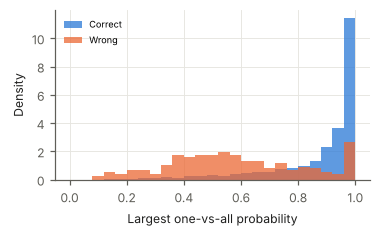

top probability < 0.5: 7.5% of test windows, 38.6% of the errors
top probability < 0.8: 24.8% of test windows, 78.8% of the errors


,both correct,only logistic regression correct,only Naive Bayes correct,both wrong
test windows,2267,491,89,100


Lowest-accuracy subject: 10


,Walk,Upstairs,Downstairs,Sit,Stand,Laying
Walk,52,0,1,0,0,0
Upstairs,11,31,4,1,0,0
Downstairs,0,0,38,0,0,0
Sit,0,0,0,33,21,0
Stand,0,0,0,6,38,0
Laying,0,0,0,0,13,45


In [53]:
# C46

off=[(activity_names[i], activity_names[j], int(final_table[i, j]))
     for i in range(n_classes) for j in range(n_classes) if i != j and final_table[i, j] > 0]
errors=pandas.DataFrame(off, columns=['true', 'predicted', 'windows']).sort_values('windows', ascending=False)
errors['share of all errors']=errors['windows']/errors['windows'].sum()
display(errors.head(8).reset_index(drop=True).round(3))
moving={'Walk', 'Upstairs', 'Downstairs'}
crossing=errors.loc[errors['true'].isin(moving) != errors['predicted'].isin(moving), 'windows'].sum()
print(f"{errors['windows'].sum()} test errors; {crossing} cross between moving and still activities")

confidence=P_test_final.max(axis=1)
correct=pred_test_final == y_test
fig, ax=plot.subplots(figsize=(col_width, 2.2))
bins=numpy.linspace(0, 1, 26)
ax.hist(confidence[correct], bins=bins, color=PALETTE['blue'], alpha=.75, density=True, label='Correct')
ax.hist(confidence[~correct], bins=bins, color=PALETTE['orange'], alpha=.75, density=True, label='Wrong')
ax.set_xlabel('Largest one-vs-all probability')
ax.set_ylabel('Density')
ax.legend(fontsize=6)
fig.tight_layout()
save_fig(fig, 'prediction_confidence')
plot.show()
for cut in (0.5, 0.8):
    low_conf=confidence < cut
    print(f'top probability < {cut}: {low_conf.mean():.1%} of test windows, {(~correct & low_conf).sum()/max((~correct).sum(), 1):.1%} of the errors')

lr_right, nb_right=pred_test_final == y_test, pred_test_nb == y_test
display(pandas.Series({'both correct': numpy.sum(lr_right & nb_right),
                       'only logistic regression correct': numpy.sum(lr_right & ~nb_right),
                       'only Naive Bayes correct': numpy.sum(~lr_right & nb_right),
                       'both wrong': numpy.sum(~lr_right & ~nb_right)}, name='test windows').to_frame().T)
worst=final_by_subject['accuracy'].idxmin()
print(f'Lowest-accuracy subject: {worst}')
display(pandas.DataFrame(confusion(y_test[subject_index[worst]], pred_test_final[subject_index[worst]], n_classes),
                         index=activity_names, columns=activity_names))

,Walk,Upstairs,Downstairs,Sit,Stand,Laying
non-zero,45,59,39,53,52,5


Features used by at least one model: 167 of 540


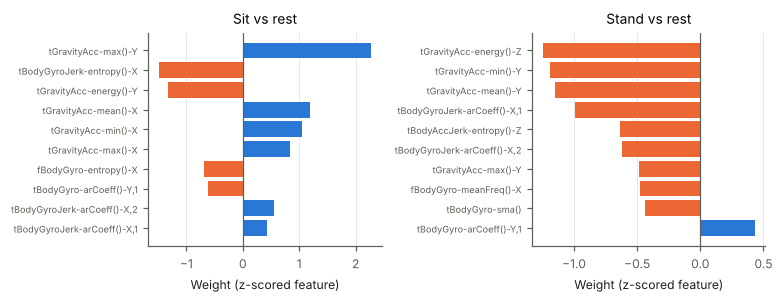

,Walk,Upstairs,Downstairs,Sit,Stand,Laying
1,fBodyAccMag-energy() (-1.78),tGravityAcc-max()-Y (-1.04),tBodyAccJerk-max()-X (+1.18),tGravityAcc-max()-Y (+2.27),tGravityAcc-energy()-Z (-1.25),tGravityAcc-min()-X (-2.50)
2,tBodyAccJerk-entropy()-Z (+1.40),tBodyAccJerk-min()-X (-0.85),fBodyAccMag-energy() (+0.80),tBodyGyroJerk-entropy()-X (-1.48),tGravityAcc-min()-Y (-1.19),tGravityAcc-mean()-X (-1.28)
3,"fBodyAcc-bandsEnergy()-1,8-X (-1.29)",fBodyGyro-max()-Z (+0.79),"fBodyAcc-bandsEnergy()-1,8-X (+0.74)",tGravityAcc-energy()-Y (-1.33),tGravityAcc-mean()-Y (-1.15),tGravityAcc-max()-X (-0.75)
4,tBodyAccJerk-entropy()-X (+1.17),fBodyBodyAccJerkMag-energy() (-0.75),"tBodyAcc-correlation()-X,Y (-0.72)",tGravityAcc-mean()-X (+1.19),"tBodyGyroJerk-arCoeff()-X,1 (-0.99)",tGravityAcc-energy()-Y (+0.12)
5,fBodyAccJerk-max()-Y (+0.82),fBodyGyro-maxInds-Z (-0.52),"tBodyGyro-correlation()-Y,Z (-0.69)",tGravityAcc-min()-X (+1.06),tBodyAccJerk-entropy()-Z (-0.63),"tBodyAcc-correlation()-Y,Z (-0.08)"


In [54]:
# C47

coef_final=final_details['coefficients']
if coef_final is not None:
    display((coef_final != 0).sum().to_frame('non-zero').T)
    print(f'Features used by at least one model: {(coef_final != 0).any(axis=1).sum()} of {len(coef_final)}')
    fig, axes=plot.subplots(1, 2, figsize=(page_width, 2.8))
    for ax, name in zip(axes, ('Sit', 'Stand')):
        top=coef_final[name][coef_final[name] != 0].abs().sort_values(ascending=False).index[:top_weights][::-1]
        values=coef_final.loc[top, name]
        ax.barh(range(len(top)), values, color=[PALETTE['blue'] if v > 0 else PALETTE['orange'] for v in values])
        ax.set_yticks(range(len(top)), top, fontsize=6)
        ax.axvline(0, color=PALETTE['ink2'], lw=.8)
        ax.set_xlabel('Weight (z-scored feature)')
        ax.set_title(f'{name} vs rest')
        ax.grid(axis='y', visible=False)
    fig.tight_layout()
    save_fig(fig, 'sit_stand_weights')
    plot.show()
    display(pandas.DataFrame({name: [f'{f} ({coef_final.loc[f, name]:+.2f})' for f in coef_final[name].abs().sort_values(ascending=False).index[:5]]
                              for name in activity_names}, index=range(1, 6)))